### **1. Import Libraries**

In [ ]:
!pip install -U pyarrow datasets

In [ ]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

## **2. Load the data**

In [ ]:
df=pd.read_csv("/content/drive/MyDrive/Colab Notebooks/Dissertation/combined_news_raw.csv")

In [ ]:
df.head()

,text,label,lang
0,In the most notable legislative work so far of...,1,en
1,"खुद को जिंदा बचाने का साल है, नफा-नुकसान मत सो...",1,hi
2,Join Patrick every Wednesday at Independent Ta...,0,en
3,"Crazy mob vandalizes, threatens, and spits at ...",0,en
4,Talk radio hosts went nuts with the news of Go...,0,en


In [ ]:
df.shape

(64859, 3)

In [ ]:
print("\nMissing values:")
display(df.isnull().sum())


Missing values:


,0
text,0
label,0
lang,0


Checking for duplicates

In [ ]:
print("\nDuplicate rows:", df.duplicated().sum())


Duplicate rows: 11122


In [ ]:
print("\nLanguage distribution:")
display(df['lang'].value_counts())


Language distribution:


,count
lang,
en,44267
hi,20592


## **3. EDA on Raw Dataset**

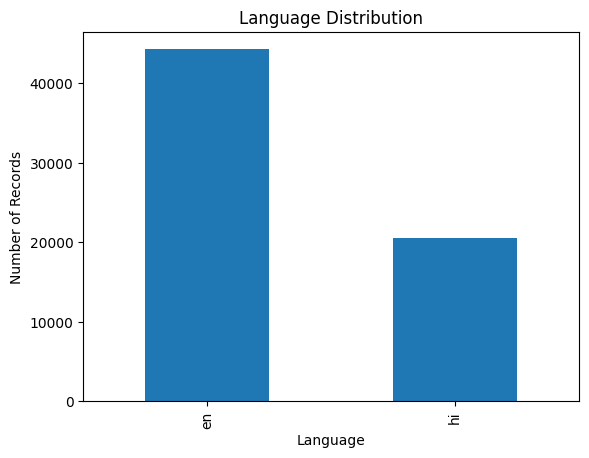

In [ ]:
df['lang'].value_counts().plot(kind='bar')
plt.title("Language Distribution")
plt.xlabel("Language")
plt.ylabel("Number of Records")
plt.show()

In [ ]:
print("\nLabel distribution:")
display(df['label'].value_counts(), df['label'].value_counts(normalize=True))


Label distribution:


,count
label,
0,33151
1,31708


,proportion
label,
0,0.511124
1,0.488876


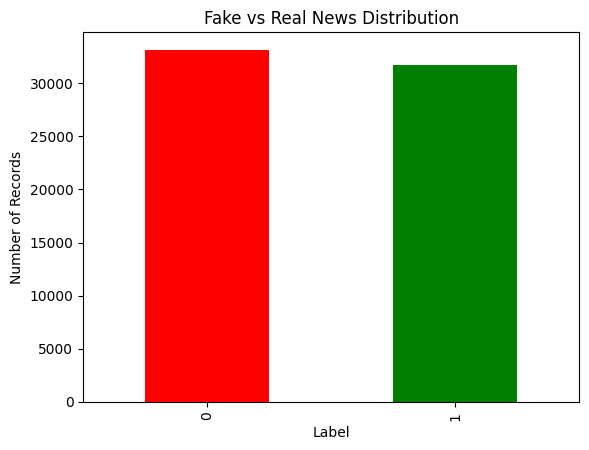

In [ ]:
df['label'].value_counts().plot(kind='bar', color=['red','green'])
plt.title("Fake vs Real News Distribution")
plt.xlabel("Label")
plt.ylabel("Number of Records")
plt.show()

In [ ]:
print("\nLabel distribution by language:")
lang_label = pd.crosstab(df['lang'], df['label'])
display(lang_label)


Label distribution by language:


label,0,1
lang,,
en,22851,21416
hi,10300,10292


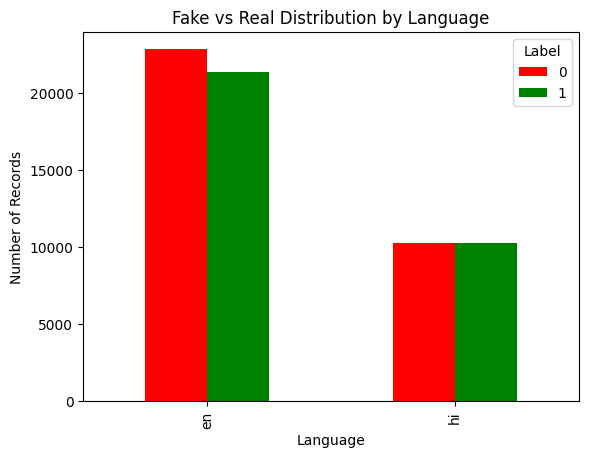

In [ ]:
lang_label.plot(kind='bar', color=['red', 'green'])
plt.title("Fake vs Real Distribution by Language")
plt.xlabel("Language")
plt.ylabel("Number of Records")
plt.legend(title="Label")
plt.show()

## **4. Data Preprocessing**

The dataset was prepared for machine learning analysis by validating the target labels and language codes, removing missing and duplicate records, and creating a cleaned version of the text. Conservative preprocessing was applied to retain meaningful English and Hindi linguistic information. The original text was preserved separately for subsequent transformer-based modelling.

In [ ]:
#creating a copy to work on
df_model=df.copy()

In [ ]:
#standardize the columns
df_model.columns=df_model.columns.str.strip().str.lower()

In [ ]:
#confirm that the required columns exist
required_columns = {"text", "label", "lang"}
missing_columns = required_columns.difference(df_model.columns)

if missing_columns:
    raise ValueError(
        f"Required columns are missing: {sorted(missing_columns)}"
    )

print("Shape before cleaning:", df_model.shape)

Shape before cleaning: (64859, 3)


In [ ]:
# Remove rows missing essential values
df_model = df_model.dropna(
    subset=["text", "label", "lang"]
).copy()

In [ ]:
# Standardise language codes
df_model["lang"] = (df_model["lang"].astype(str).str.strip().str.lower())

In [ ]:
# Retain only English and Hindi records
df_model = df_model[df_model["lang"].isin(["en", "hi"])].copy()

In [ ]:
# Convert labels to numeric values
df_model["label"] = pd.to_numeric(
    df_model["label"],
    errors="coerce"
)

df_model = df_model.dropna(subset=["label"]).copy()
df_model["label"] = df_model["label"].astype(int)

In [ ]:
# Retain binary labels only
df_model = df_model[
    df_model["label"].isin([0, 1])
].copy()

In [ ]:
# Remove exact duplicate rows
exact_duplicates = df_model.duplicated().sum()
df_model = df_model.drop_duplicates().copy()

In [ ]:
# Remove duplicated news text
text_duplicates = df_model.duplicated(
    subset=["text"]
).sum()

df_model = df_model.drop_duplicates(
    subset=["text"],
    keep="first"
).copy()

df_model = df_model.reset_index(drop=True)

print("Exact duplicate rows removed:", exact_duplicates)
print("Duplicate text records removed:", text_duplicates)
print("Shape after cleaning:", df_model.shape)


Exact duplicate rows removed: 11122
Duplicate text records removed: 0
Shape after cleaning: (53737, 3)


In [ ]:
print("\nMissing values after cleaning:")
display(df_model[["text", "label", "lang"]].isna().sum())


Missing values after cleaning:


,0
text,0
label,0
lang,0


In [ ]:
#verify label meaning
print("Unique label values:", df_model["label"].unique())

display(df_model.groupby(["lang", "label"]).size().reset_index(name="count"))

Unique label values: [1 0]


,lang,label,count
0,en,0,17449
1,en,1,21189
2,hi,0,7599
3,hi,1,7500


In [ ]:
LABEL_MAP = {
    0: "Fake",
    1: "Real"
}

df_model["label_name"] = df_model["label"].map(LABEL_MAP)

display(
    df_model["label_name"]
    .value_counts()
    .rename_axis("class")
    .reset_index(name="count")
)

,class,count
0,Real,28689
1,Fake,25048


### **4.1 Text Cleaning**

In [ ]:
import re
import unicodedata
import html

def clean_multilingual_text(text: str) -> str:
    """
    Light cleaning for English and Hindi text while preserving
    sentence structure and linguistic information.

    Processing:
    - Unicode normalisation
    - Decode HTML entities
    - Remove URLs
    - Remove email addresses
    - Remove HTML tags
    - Normalise excessive whitespace

    Intentionally preserved:
    - Original language
    - Hindi matras and Unicode characters
    - Punctuation
    - Sentence structure
    - Word order
    - Letter case
    """

    text = str(text)

    # Standardise Unicode representation
    text = unicodedata.normalize("NFC", text)

    # Decode HTML entities such as &amp;
    text = html.unescape(text)

    # Remove URLs
    text = re.sub(r"https?://\S+|www\.\S+", " ", text)

    # Remove email addresses
    text = re.sub(r"\S+@\S+", " ", text)

    # Remove HTML tags
    text = re.sub(r"<[^>]+>", " ", text)

    # Replace repeated whitespace while retaining sentence structure
    text = re.sub(r"\s+", " ", text).strip()

    return text

In [ ]:
# Preserve the original text
df_model["text_raw"] = df_model["text"].astype(str)

# Apply light multilingual text cleaning
df_model["text_clean"] = df_model["text_raw"].apply(
    clean_multilingual_text
)

display(
    df_model[
        ["lang", "label_name", "text_raw", "text_clean"]
    ].head()
)

,lang,label_name,text_raw,text_clean
0,en,Real,In the most notable legislative work so far of...,In the most notable legislative work so far of...
1,hi,Real,"खुद को जिंदा बचाने का साल है, नफा-नुकसान मत सो...","खुद को जिंदा बचाने का साल है, नफा-नुकसान मत सो..."
2,en,Fake,Join Patrick every Wednesday at Independent Ta...,Join Patrick every Wednesday at Independent Ta...
3,en,Fake,"Crazy mob vandalizes, threatens, and spits at ...","Crazy mob vandalizes, threatens, and spits at ..."
4,en,Fake,Talk radio hosts went nuts with the news of Go...,Talk radio hosts went nuts with the news of Go...


In [ ]:
# Final validation of the modelling dataset

print("Final dataset shape:", df_model.shape)

print("\nMissing values:")
display(
    df_model[
        ["text_raw", "text_clean", "label", "label_name", "lang"]
    ].isna().sum()
)

print("\nEmpty cleaned-text records:")
empty_text = (
    df_model["text_clean"]
    .astype(str)
    .str.strip()
    .eq("")
    .sum()
)
print(empty_text)

print("\nDuplicate cleaned-text records:")
print(df_model.duplicated(subset=["text_clean"]).sum())

Final dataset shape: (53737, 6)

Missing values:


,0
text_raw,0
text_clean,0
label,0
label_name,0
lang,0



Empty cleaned-text records:
53

Duplicate cleaned-text records:
101


In [ ]:
# Investigate records that became empty after text cleaning

empty_records = df_model[
    df_model["text_clean"].astype(str).str.strip().eq("")
]

print("Number of empty cleaned records:", len(empty_records))

display(
    empty_records[
        ["lang", "label_name", "text_raw", "text_clean"]
    ]
)

Number of empty cleaned records: 53


,lang,label_name,text_raw,text_clean
416,en,Fake,https://www.youtube.com/watch?v=6VN1maBEKIk,
1294,en,Fake,https://www.youtube.com/watch?time_continue=13...,
1862,en,Fake,https://www.youtube.com/watch?feature=player_e...,
1970,en,Fake,https://www.youtube.com/watch?v=1RVqTfIKGbU,
2710,en,Fake,https://www.youtube.com/watch?v=IioEIUmawRo,
3921,en,Fake,https://www.youtube.com/watch?v=9LNyx_DWzzA,
4284,en,Fake,https://www.youtube.com/watch?v=J4LjxrOfEF8,
4818,en,Fake,https://www.youtube.com/watch?v=0cVugq2GbBk,
6419,en,Fake,https://www.youtube.com/watch?v=yRXmFmgoPTk,
6762,en,Fake,https://youtu.be/RTuxvWjH3a4,


In [ ]:
# Investigate duplicate cleaned-text records

duplicate_records = df_model[
    df_model.duplicated(
        subset=["text_clean"],
        keep=False
    )
].sort_values("text_clean")

print(
    "Total rows involved in duplicated text:",
    len(duplicate_records)
)

display(
    duplicate_records[
        ["lang", "label_name", "text_raw", "text_clean"]
    ].head(30)
)

Total rows involved in duplicated text: 151


,lang,label_name,text_raw,text_clean
14748,en,Fake,https://www.youtube.com/watch?v=sMHGkzrwzKg,
23162,en,Fake,https://youtu.be/7oOhwHG2Gb4,
30493,en,Fake,https://twitter.com/Rosie/status/8009393386158...,
12488,en,Fake,https://www.youtube.com/watch?time_continue=1&...,
12767,en,Fake,https://www.youtube.com/watch?v=RRPSCqkAJgk,
13498,en,Fake,https://www.youtube.com/watch?v=ISm-p8e-D7I,
14395,en,Fake,https://youtu.be/Ai5ayloRa-0,
26667,en,Fake,https://www.youtube.com/watch?v=_FNt3ns_EGA,
14798,en,Fake,https://www.youtube.com/watch?v=P-TBfkqk7gU,
38032,en,Fake,https://www.youtube.com/watch?v=tY0ApLE6dns,


In [ ]:
# Check whether identical cleaned text has conflicting labels

label_conflicts = (
    df_model.groupby("text_clean")["label"]
    .nunique()
)

conflicting_texts = label_conflicts[
    label_conflicts > 1
].index

conflicting_records = (
    df_model[
        df_model["text_clean"].isin(conflicting_texts)
    ]
    .sort_values("text_clean")
)

print(
    "Number of unique texts with conflicting labels:",
    len(conflicting_texts)
)

display(
    conflicting_records[
        ["lang", "label_name", "text_raw", "text_clean"]
    ].head(30)
)

Number of unique texts with conflicting labels: 2


,lang,label_name,text_raw,text_clean
27737,hi,Real,ज़ी न्यूज़ के एंकर को छत्तीसगढ़ पुलिस के गिरफ़...,ज़ी न्यूज़ के एंकर को छत्तीसगढ़ पुलिस के गिरफ़...
28030,hi,Fake,ज़ी न्यूज़ के एंकर को छत्तीसगढ़ पुलिस के गिरफ़...,ज़ी न्यूज़ के एंकर को छत्तीसगढ़ पुलिस के गिरफ़...
9931,hi,Fake,राहुल गांधी का बयान उदयपुर हत्या से जोड़कर ‘झू...,राहुल गांधी का बयान उदयपुर हत्या से जोड़कर ‘झू...
40352,hi,Real,राहुल गांधी का बयान उदयपुर हत्या से जोड़कर ‘झू...,राहुल गांधी का बयान उदयपुर हत्या से जोड़कर ‘झू...


### **4.2 Removal of Non-Informative and Conflicting Records**

Records containing no textual information following URL and HTML removal were excluded because they could not contribute linguistic features to the text-classification task.

Identical text records assigned conflicting class labels were also excluded because a reliable ground-truth classification could not be established.

In [ ]:
# Record dataset size before final quality filtering
rows_before = len(df_model)

# 1. Remove records with no textual content after cleaning
df_model = df_model[
    df_model["text_clean"].astype(str).str.strip().ne("")
].copy()

rows_after_empty = len(df_model)

print("Removed empty cleaned-text records:",
      rows_before - rows_after_empty)


# 2. Identify identical texts assigned conflicting labels
label_counts = (
    df_model.groupby("text_clean")["label"]
    .nunique()
)

conflicting_texts = label_counts[
    label_counts > 1
].index

print("Unique conflicting texts:",
      len(conflicting_texts))


# Remove all records associated with conflicting texts
df_model = df_model[
    ~df_model["text_clean"].isin(conflicting_texts)
].copy()

rows_after_conflicts = len(df_model)

print("Records removed due to conflicting labels:",
      rows_after_empty - rows_after_conflicts)

print("\nFinal dataset size:",
      df_model.shape)

Removed empty cleaned-text records: 53
Unique conflicting texts: 2
Records removed due to conflicting labels: 4

Final dataset size: (53680, 6)


In [ ]:
# Recheck duplicate texts after removing empty and conflicting records

duplicate_count = df_model.duplicated(
    subset=["text_clean"]
).sum()

duplicate_rows = df_model[
    df_model.duplicated(
        subset=["text_clean"],
        keep=False
    )
]

print("Remaining duplicate cleaned-text records:",
      duplicate_count)

print("Total rows involved in remaining duplicates:",
      len(duplicate_rows))

display(
    duplicate_rows[
        ["lang", "label_name", "text_raw", "text_clean"]
    ].sort_values("text_clean").head(30)
)

Remaining duplicate cleaned-text records: 47
Total rows involved in remaining duplicates: 94


,lang,label_name,text_raw,text_clean
15357,hi,Real,'बीबीसी के नाम' पर वायरल की जा रही रोहिंग्या त...,'बीबीसी के नाम' पर वायरल की जा रही रोहिंग्या त...
1922,hi,Real,'बीबीसी के नाम' पर वायरल की जा रही रोहिंग्या त...,'बीबीसी के नाम' पर वायरल की जा रही रोहिंग्या त...
49324,hi,Real,'मोदी के गुरु' संभाजी भिड़े के नासा विज्ञानी ह...,'मोदी के गुरु' संभाजी भिड़े के नासा विज्ञानी ह...
25927,hi,Real,'मोदी के गुरु' संभाजी भिड़े के नासा विज्ञानी ह...,'मोदी के गुरु' संभाजी भिड़े के नासा विज्ञानी ह...
16619,en,Real,Some key U.S. senators still had concerns abou...,Some key U.S. senators still had concerns abou...
49952,en,Real,Some key U.S. senators still had concerns abou...,Some key U.S. senators still had concerns abou...
32631,hi,Real,अनुच्छेद- के समर्थन में कश्मीरी मुसलमानों के ज...,अनुच्छेद- के समर्थन में कश्मीरी मुसलमानों के ज...
36306,hi,Real,अनुच्छेद- के समर्थन में कश्मीरी मुसलमानों के ज...,अनुच्छेद- के समर्थन में कश्मीरी मुसलमानों के ज...
12322,hi,Real,असदउद्दीन ओवैसी ने इंडिया गेट के सारे 'नंबर' ग...,असदउद्दीन ओवैसी ने इंडिया गेट के सारे 'नंबर' ग...
11072,hi,Real,असदउद्दीन ओवैसी ने इंडिया गेट के सारे 'नंबर' ग...,असदउद्दीन ओवैसी ने इंडिया गेट के सारे 'नंबर' ग...


In [ ]:
# Final verification of remaining duplicate pairs

duplicate_check = (
    duplicate_rows
    .groupby("text_clean")
    .agg(
        number_of_records=("text_clean", "size"),
        number_of_labels=("label", "nunique"),
        number_of_languages=("lang", "nunique")
    )
)

display(duplicate_check.head(20))

print(
    "Duplicates with different labels:",
    (duplicate_check["number_of_labels"] > 1).sum()
)

print(
    "Duplicates appearing across different languages:",
    (duplicate_check["number_of_languages"] > 1).sum()
)

print(
    "Maximum number of occurrences of one text:",
    duplicate_check["number_of_records"].max()
)

number_of_records  \
text_clean                                                              
'बीबीसी के नाम' पर वायरल की जा रही रोहिंग्या तस...                  2   
'मोदी के गुरु' संभाजी भिड़े के नासा विज्ञानी हो...                  2   
Some key U.S. senators still had concerns about...                  2   
अनुच्छेद- के समर्थन में कश्मीरी मुसलमानों के जु...                  2   
असदउद्दीन ओवैसी ने इंडिया गेट के सारे 'नंबर' ग़...                  2   
इमरान ख़ान का ऐलान, ‘शिया शून्य’ होगा पाकिस्तान...                  2   
कश्मीर के नाम पर पाकिस्तान में वायरल फ़र्ज़ी ख़...                  2   
कश्मीरअनुच्छेद को लेकर किए जा रहे दावों की पड़त...                  2   
कश्मीरभारतीय सैनिक की इस वायरल तस्वीर का पूरा स...                  2   
कश्मीरी घरों में सेना के आग लगाने का सचफ़ैक्ट च...                  2   
कश्मीर‘विरोध का प्रतीक’ बनी इस वायरल तस्वीर की ...                  2   
का विरोध करने पर 'अखिलेश की गिरफ़्तारी' का सचफ़...                  2   
कांवड़ यात्रामुस्लिम लड़कियों के शिव मंदिर में ...                  2   
कारों की बिक्री कम होने मेंका कितना असर? फ़ैक्ट...                  2   
किसान को पीटते अफ़सर के वायरल वीडियो का सच किसा...                  2   
केरल के बताए जा रहे छेड़छाड़ वाले वायरल वीडियो ...                  2   
कोरोना वायरस का इलाज है काली मिर्च- इस दावे का ...                  2   
कोरोना वायरस टेस्ट कराने से मस्तिष्क पर असर पड़...                  2   
क्या 'जय श्री राम' ना बोलने पर हुई अब्दुल ख़ालि...                  2   
क्या अनुच्छेद- पर पत्रकारों से भिड़े पाकिस्तान ...                  2   

                                                    number_of_labels  \
text_clean                                                             
'बीबीसी के नाम' पर वायरल की जा रही रोहिंग्या तस...                 1   
'मोदी के गुरु' संभाजी भिड़े के नासा विज्ञानी हो...                 1   
Some key U.S. senators still had concerns about...                 1   
अनुच्छेद- के समर्थन में कश्मीरी मुसलमानों के जु...                 1   
असदउद्दीन ओवैसी ने इंडिया गेट के सारे 'नंबर' ग़...                 1   
इमरान ख़ान का ऐलान, ‘शिया शून्य’ होगा पाकिस्तान...                 1   
कश्मीर के नाम पर पाकिस्तान में वायरल फ़र्ज़ी ख़...                 1   
कश्मीरअनुच्छेद को लेकर किए जा रहे दावों की पड़त...                 1   
कश्मीरभारतीय सैनिक की इस वायरल तस्वीर का पूरा स...                 1   
कश्मीरी घरों में सेना के आग लगाने का सचफ़ैक्ट च...                 1   
कश्मीर‘विरोध का प्रतीक’ बनी इस वायरल तस्वीर की ...                 1   
का विरोध करने पर 'अखिलेश की गिरफ़्तारी' का सचफ़...                 1   
कांवड़ यात्रामुस्लिम लड़कियों के शिव मंदिर में ...                 1   
कारों की बिक्री कम होने मेंका कितना असर? फ़ैक्ट...                 1   
किसान को पीटते अफ़सर के वायरल वीडियो का सच किसा...                 1   
केरल के बताए जा रहे छेड़छाड़ वाले वायरल वीडियो ...                 1   
कोरोना वायरस का इलाज है काली मिर्च- इस दावे का ...                 1   
कोरोना वायरस टेस्ट कराने से मस्तिष्क पर असर पड़...                 1   
क्या 'जय श्री राम' ना बोलने पर हुई अब्दुल ख़ालि...                 1   
क्या अनुच्छेद- पर पत्रकारों से भिड़े पाकिस्तान ...                 1   

                                                    number_of_languages  
text_clean                                                               
'बीबीसी के नाम' पर वायरल की जा रही रोहिंग्या तस...                    1  
'मोदी के गुरु' संभाजी भिड़े के नासा विज्ञानी हो...                    1  
Some key U.S. senators still had concerns about...                    1  
अनुच्छेद- के समर्थन में कश्मीरी मुसलमानों के जु...                    1  
असदउद्दीन ओवैसी ने इंडिया गेट के सारे 'नंबर' ग़...                    1  
इमरान ख़ान का ऐलान, ‘शिया शून्य’ होगा पाकिस्तान...                    1  
कश्मीर के नाम पर पाकिस्तान में वायरल फ़र्ज़ी ख़...                    1  
कश्मीरअनुच्छेद को लेकर किए जा रहे दावों की पड़त...                    1  
कश्मीरभारतीय सैनिक की इस वायरल तस्वीर का पूरा स...                    1  
कश्मीरी घरों में सेना के आग लगाने का सचफ़ैक्ट 

Duplicates with different labels: 0
Duplicates appearing across different languages: 0
Maximum number of occurrences of one text: 2


In [ ]:
# Remove genuine same-label duplicate records

rows_before_deduplication = len(df_model)

df_model = (
    df_model
    .drop_duplicates(
        subset=["text_clean"],
        keep="first"
    )
    .copy()
)

rows_after_deduplication = len(df_model)

print(
    "Duplicate records removed:",
    rows_before_deduplication - rows_after_deduplication
)

print(
    "Final modelling dataset shape:",
    df_model.shape
)

print(
    "Remaining duplicate texts:",
    df_model.duplicated(subset=["text_clean"]).sum()
)

Duplicate records removed: 47
Final modelling dataset shape: (53633, 6)
Remaining duplicate texts: 0


## **5. Exploratory Data Analysis**

Exploratory data analysis was conducted on the final cleaned dataset to examine
the distribution of languages, class labels and textual characteristics before
model development.

In [ ]:
# Dataset Distribution by Language and Class

# Overall language distribution
language_distribution = (
    df_model["lang"]
    .value_counts()
    .rename_axis("Language")
    .reset_index(name="Count")
)

language_distribution["Percentage"] = (
    language_distribution["Count"]
    / language_distribution["Count"].sum()
    * 100
).round(2)

print("LANGUAGE DISTRIBUTION")
display(language_distribution)


# Overall class distribution
class_distribution = (
    df_model["label_name"]
    .value_counts()
    .rename_axis("Class")
    .reset_index(name="Count")
)

class_distribution["Percentage"] = (
    class_distribution["Count"]
    / class_distribution["Count"].sum()
    * 100
).round(2)

print("\nOVERALL CLASS DISTRIBUTION")
display(class_distribution)


# Fake/Real distribution within each language
language_class_counts = pd.crosstab(
    df_model["lang"],
    df_model["label_name"]
)

print("\nCLASS DISTRIBUTION BY LANGUAGE")
display(language_class_counts)


# Percentage distribution within each language
language_class_percent = pd.crosstab(
    df_model["lang"],
    df_model["label_name"],
    normalize="index"
).mul(100).round(2)

print("\nCLASS PERCENTAGE WITHIN EACH LANGUAGE")
display(language_class_percent)

LANGUAGE DISTRIBUTION


,Language,Count,Percentage
0,en,38584,71.94
1,hi,15049,28.06



OVERALL CLASS DISTRIBUTION


,Class,Count,Percentage
0,Real,28640,53.4
1,Fake,24993,46.6



CLASS DISTRIBUTION BY LANGUAGE


label_name,Fake,Real
lang,,
en,17396,21188
hi,7597,7452



CLASS PERCENTAGE WITHIN EACH LANGUAGE


label_name,Fake,Real
lang,,
en,45.09,54.91
hi,50.48,49.52


In [ ]:
# Text Length Analysis

# Word count
df_model["word_count"] = (
    df_model["text_clean"]
    .astype(str)
    .str.split()
    .str.len()
)

# Character count
df_model["char_count"] = (
    df_model["text_clean"]
    .astype(str)
    .str.len()
)

# Summary statistics by language
text_length_summary = (
    df_model
    .groupby("lang")[["word_count", "char_count"]]
    .describe()
    .round(2)
)

display(text_length_summary)

word_count                                                   char_count  \
          count    mean     std  min    25%    50%    75%     max      count   
lang                                                                           
en      38584.0  401.06  313.36  1.0  215.0  367.0  509.0  8135.0    38584.0   
hi      15049.0  670.66  395.89  7.0  409.0  563.0  807.0  9167.0    15049.0   

                                                               
         mean      std   min     25%     50%     75%      max  
lang                                                           
en    2423.10  1916.50   5.0  1299.0  2201.0  3053.0  51493.0  
hi    3503.92  2138.24  37.0  2106.0  2901.0  4191.0  53201.0

In [ ]:
# Text-length percentiles by language

percentiles = [0.50, 0.75, 0.90, 0.95, 0.99]

for language in ["en", "hi"]:

    subset = df_model.loc[
        df_model["lang"] == language,
        "word_count"
    ]

    print(f"\n{language.upper()} WORD-COUNT PERCENTILES")

    for p in percentiles:
        print(
            f"{int(p * 100)}th percentile:",
            round(subset.quantile(p))
        )

    print("Maximum:", subset.max())


EN WORD-COUNT PERCENTILES
50th percentile: 367
75th percentile: 509
90th percentile: 730
95th percentile: 877
99th percentile: 1307
Maximum: 8135

HI WORD-COUNT PERCENTILES
50th percentile: 563
75th percentile: 807
90th percentile: 1274
95th percentile: 1385
99th percentile: 1855
Maximum: 9167


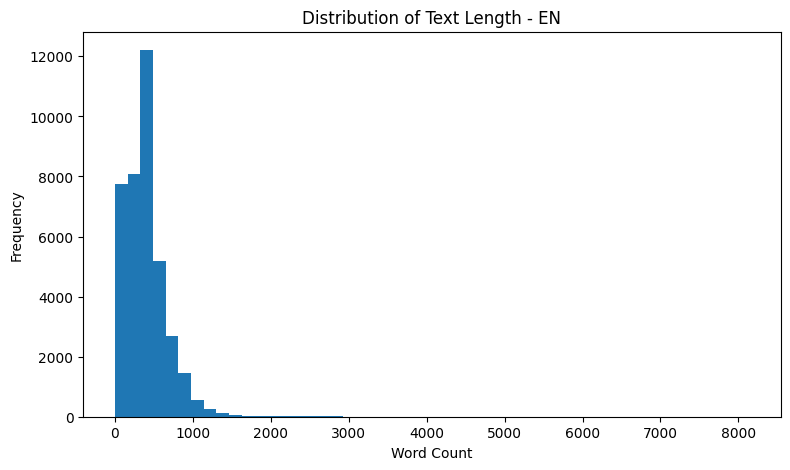

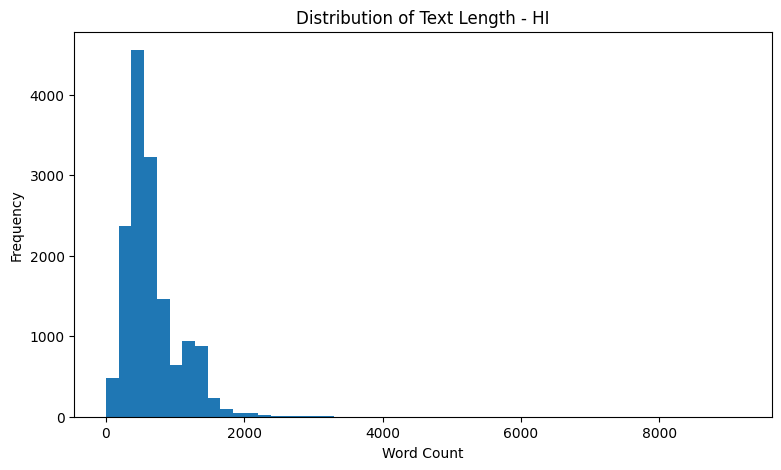

In [ ]:
import matplotlib.pyplot as plt

for language in ["en", "hi"]:

    subset = df_model[
        df_model["lang"] == language
    ]

    plt.figure(figsize=(9, 5))

    plt.hist(
        subset["word_count"],
        bins=50
    )

    plt.title(
        f"Distribution of Text Length - {language.upper()}"
    )
    plt.xlabel("Word Count")
    plt.ylabel("Frequency")

    plt.show()

## **6. Train-Test Split**

In [ ]:
from sklearn.model_selection import train_test_split

# Separate English and Hindi datasets

df_en = df_model[
    df_model["lang"] == "en"
].copy()

df_hi = df_model[
    df_model["lang"] == "hi"
].copy()

print("English dataset:", df_en.shape)
print("Hindi dataset:", df_hi.shape)

English dataset: (38584, 8)
Hindi dataset: (15049, 8)


In [ ]:
# Stratified 80:20 Train-Test Split

# English
X_train_en, X_test_en, y_train_en, y_test_en = train_test_split(
    df_en["text_clean"],
    df_en["label"],
    test_size=0.20,
    random_state=42,
    stratify=df_en["label"]
)

# Hindi
X_train_hi, X_test_hi, y_train_hi, y_test_hi = train_test_split(
    df_hi["text_clean"],
    df_hi["label"],
    test_size=0.20,
    random_state=42,
    stratify=df_hi["label"]
)

print("ENGLISH")
print("Training:", len(X_train_en))
print("Testing :", len(X_test_en))

print("\nHINDI")
print("Training:", len(X_train_hi))
print("Testing :", len(X_test_hi))

ENGLISH
Training: 30867
Testing : 7717

HINDI
Training: 12039
Testing : 3010


In [ ]:
# Verify class balance after splitting

def check_split(name, y_train, y_test):

    print(f"\n{name}")

    print("\nTraining class distribution (%)")
    print(
        y_train.value_counts(normalize=True)
        .sort_index()
        .mul(100)
        .round(2)
    )

    print("\nTesting class distribution (%)")
    print(
        y_test.value_counts(normalize=True)
        .sort_index()
        .mul(100)
        .round(2)
    )


check_split(
    "ENGLISH",
    y_train_en,
    y_test_en
)

check_split(
    "HINDI",
    y_train_hi,
    y_test_hi
)


ENGLISH

Training class distribution (%)
label
0    45.09
1    54.91
Name: proportion, dtype: float64

Testing class distribution (%)
label
0    45.08
1    54.92
Name: proportion, dtype: float64

HINDI

Training class distribution (%)
label
0    50.48
1    49.52
Name: proportion, dtype: float64

Testing class distribution (%)
label
0    50.5
1    49.5
Name: proportion, dtype: float64


## **7. Feature Representation**

Traditional machine learning models require numerical representations of textual
data. TF-IDF vectorisation is therefore applied separately to the English and
Hindi datasets. To prevent data leakage, each vectorizer is fitted only on its
respective training data and subsequently used to transform the corresponding
test data.

Three traditional classification models are evaluated:
- Logistic Regression
- Support Vector Machine
- Random Forest

Limited hyperparameter tuning is conducted using the training data only. The
held-out test datasets remain untouched until final model evaluation.

In [ ]:
from sklearn.feature_extraction.text import TfidfVectorizer

# Initial TF-IDF Vocabulary Analysis on training data

def analyse_tfidf_vocabulary(texts, language):

    vectorizer = TfidfVectorizer(
        lowercase=True,
        ngram_range=(1, 2),
        min_df=2,
        max_df=0.95
    )

    X_temp = vectorizer.fit_transform(texts)

    print(f"{language} TF-IDF ANALYSIS")
    print("-" * 40)
    print("Training documents:", X_temp.shape[0])
    print("Vocabulary size:", X_temp.shape[1])
    print("Matrix shape:", X_temp.shape)
    print(
        "Matrix density:",
        round(
            X_temp.nnz /
            (X_temp.shape[0] * X_temp.shape[1]),
            6
        )
    )

    return vectorizer


tfidf_analysis_en = analyse_tfidf_vocabulary(
    X_train_en,
    "ENGLISH"
)

print()

tfidf_analysis_hi = analyse_tfidf_vocabulary(
    X_train_hi,
    "HINDI"
)

ENGLISH TF-IDF ANALYSIS
----------------------------------------
Training documents: 30867
Vocabulary size: 835849
Matrix shape: (30867, 835849)
Matrix density: 0.000606

HINDI TF-IDF ANALYSIS
----------------------------------------
Training documents: 12039
Vocabulary size: 205600
Matrix shape: (12039, 205600)
Matrix density: 0.001932


### **7.1 TF-IDF Feature-Space Selection**

Initial vocabulary analysis produced 835,849 English features and 205,600 Hindi
features when unigrams and bigrams were retained without an explicit feature
limit. A controlled feature space was therefore evaluated to reduce
dimensionality and computational cost.

Candidate maximum feature sizes of 20,000, 40,000 and 60,000 were compared
using Logistic Regression and stratified cross-validation on the training data.
F1-score was used as the primary selection criterion. The held-out test data
were not used during feature-space selection.

In [ ]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.pipeline import Pipeline
import pandas as pd
import time

feature_sizes = [20000, 40000, 60000]

cv = StratifiedKFold(
    n_splits=3,
    shuffle=True,
    random_state=42
)

def evaluate_feature_sizes(X_train, y_train, language):

    results = []

    for max_features in feature_sizes:

        print(
            f"{language}: evaluating "
            f"max_features={max_features:,}..."
        )

        start = time.time()

        pipeline = Pipeline([
            (
                "tfidf",
                TfidfVectorizer(
                    lowercase=True,
                    ngram_range=(1, 2),
                    min_df=2,
                    max_df=0.95,
                    max_features=max_features,
                    sublinear_tf=True
                )
            ),
            (
                "model",
                LogisticRegression(
                    max_iter=1000,
                    random_state=42
                )
            )
        ])

        scores = cross_val_score(
            pipeline,
            X_train,
            y_train,
            cv=cv,
            scoring="f1_macro",
            n_jobs=-1
        )

        results.append({
            "Language": language,
            "Max Features": max_features,
            "Mean CV F1": scores.mean(),
            "Std CV F1": scores.std(),
            "Time (seconds)": time.time() - start
        })

    return pd.DataFrame(results)


tfidf_results_en = evaluate_feature_sizes(
    X_train_en,
    y_train_en,
    "English"
)

tfidf_results_hi = evaluate_feature_sizes(
    X_train_hi,
    y_train_hi,
    "Hindi"
)

tfidf_feature_results = pd.concat(
    [tfidf_results_en, tfidf_results_hi],
    ignore_index=True
)

print("\nTF-IDF FEATURE-SELECTION RESULTS")
display(tfidf_feature_results)

English: evaluating max_features=20,000...
English: evaluating max_features=40,000...
English: evaluating max_features=60,000...
Hindi: evaluating max_features=20,000...
Hindi: evaluating max_features=40,000...
Hindi: evaluating max_features=60,000...

TF-IDF FEATURE-SELECTION RESULTS


,Language,Max Features,Mean CV F1,Std CV F1,Time (seconds)
0,English,20000,0.983325,0.001151,29.832508
1,English,40000,0.982834,0.000802,30.406219
2,English,60000,0.981523,0.001502,30.610062
3,Hindi,20000,0.990030,0.001763,12.383729
4,Hindi,40000,0.989448,0.001528,10.838204
5,Hindi,60000,0.989531,0.001590,11.199553


### **7.2 Final TF-IDF Representation**

Based on the training-set cross-validation results, a maximum vocabulary size of
20,000 features was selected for both language datasets. This configuration
achieved the highest mean validation F1-score for both English and Hindi while
maintaining a lower-dimensional feature space.

Separate TF-IDF vectorizers were fitted to the complete English and Hindi
training sets. The fitted vectorizers were then used to transform their
corresponding held-out test sets.

In [ ]:
final_tfidf_params = {
    "lowercase": True,
    "ngram_range": (1, 2),
    "min_df": 2,
    "max_df": 0.95,
    "max_features": 20000,
    "sublinear_tf": True
}

# Separate vectorizers for English and Hindi
tfidf_en = TfidfVectorizer(**final_tfidf_params)
tfidf_hi = TfidfVectorizer(**final_tfidf_params)

# Fit ONLY on training data
X_train_en_tfidf = tfidf_en.fit_transform(X_train_en)
X_train_hi_tfidf = tfidf_hi.fit_transform(X_train_hi)

# Transform held-out test data
X_test_en_tfidf = tfidf_en.transform(X_test_en)
X_test_hi_tfidf = tfidf_hi.transform(X_test_hi)

print("FINAL TF-IDF MATRICES")
print("-" * 45)

print("English:")
print(" Training:", X_train_en_tfidf.shape)
print(" Testing: ", X_test_en_tfidf.shape)
print(" Vocabulary:", len(tfidf_en.vocabulary_))

print("\nHindi:")
print(" Training:", X_train_hi_tfidf.shape)
print(" Testing: ", X_test_hi_tfidf.shape)
print(" Vocabulary:", len(tfidf_hi.vocabulary_))

FINAL TF-IDF MATRICES
---------------------------------------------
English:
 Training: (30867, 20000)
 Testing:  (7717, 20000)
 Vocabulary: 20000

Hindi:
 Training: (12039, 20000)
 Testing:  (3010, 20000)
 Vocabulary: 20000


## **8. Traditional Machine Learning Model Selection**

Three traditional machine learning classifiers were evaluated: Logistic
Regression (LR), Support Vector Machine (SVM) and Random Forest (RF).

A limited hyperparameter search was conducted using stratified three-fold
cross-validation on the training data. F1-score was used as the primary
selection metric. Hyperparameter selection was performed independently for
English and Hindi, while the same candidate parameter space was used for both
languages.

The held-out test sets were not used during model selection.

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedKFold, GridSearchCV
import time

# Traditional ML Hyperparameter Tuning on training data

cv = StratifiedKFold(
    n_splits=3,
    shuffle=True,
    random_state=42
)

models_and_params = {

    "Logistic Regression": {
        "model": LogisticRegression(
            max_iter=2000,
            random_state=42
        ),
        "params": {
            "C": [0.5, 1.0, 2.0]
        }
    },

    "SVM": {
        "model": LinearSVC(
            random_state=42
        ),
        "params": {
            "C": [0.5, 1.0, 2.0]
        }
    },

    "Random Forest": {
        "model": RandomForestClassifier(
            random_state=42,
            n_jobs=-1
        ),
        "params": {
            "n_estimators": [200, 400],
            "max_depth": [None, 50]
        }
    }
}


def tune_models(X_train, y_train, language):

    results = []
    fitted_searches = {}

    for model_name, config in models_and_params.items():

        print(f"\n{language} - {model_name}")
        print("-" * 45)

        start = time.time()

        search = GridSearchCV(
            estimator=config["model"],
            param_grid=config["params"],
            scoring="f1_macro",
            cv=cv,
            n_jobs=-1,
            refit=True
        )

        search.fit(X_train, y_train)

        elapsed = time.time() - start

        print("Best parameters:", search.best_params_)
        print("Best CV F1:", round(search.best_score_, 6))
        print("Time (seconds):", round(elapsed, 2))

        results.append({
            "Language": language,
            "Model": model_name,
            "Best Parameters": search.best_params_,
            "Best CV F1": search.best_score_,
            "Time (seconds)": elapsed
        })

        fitted_searches[model_name] = search

    return pd.DataFrame(results), fitted_searches

In [ ]:
# English model tuning
tuning_results_en, searches_en = tune_models(
    X_train_en_tfidf,
    y_train_en,
    "English"
)

# Hindi model tuning
tuning_results_hi, searches_hi = tune_models(
    X_train_hi_tfidf,
    y_train_hi,
    "Hindi"
)

tuning_results = pd.concat(
    [tuning_results_en, tuning_results_hi],
    ignore_index=True
)

print("\nFINAL TUNING SUMMARY")
display(tuning_results)


English - Logistic Regression
---------------------------------------------
Best parameters: {'C': 2.0}
Best CV F1: 0.985754
Time (seconds): 3.03

English - SVM
---------------------------------------------
Best parameters: {'C': 1.0}
Best CV F1: 0.990932
Time (seconds): 2.98

English - Random Forest
---------------------------------------------
Best parameters: {'max_depth': None, 'n_estimators': 400}
Best CV F1: 0.97774
Time (seconds): 238.66

Hindi - Logistic Regression
---------------------------------------------
Best parameters: {'C': 2.0}
Best CV F1: 0.990362
Time (seconds): 2.93

Hindi - SVM
---------------------------------------------
Best parameters: {'C': 2.0}
Best CV F1: 0.992606
Time (seconds): 0.75

Hindi - Random Forest
---------------------------------------------
Best parameters: {'max_depth': None, 'n_estimators': 400}
Best CV F1: 0.989699
Time (seconds): 47.46

FINAL TUNING SUMMARY


,Language,Model,Best Parameters,Best CV F1,Time (seconds)
0,English,Logistic Regression,{'C': 2.0},0.985754,3.033046
1,English,SVM,{'C': 1.0},0.990932,2.975961
2,English,Random Forest,"{'max_depth': None, 'n_estimators': 400}",0.977740,238.658673
3,Hindi,Logistic Regression,{'C': 2.0},0.990362,2.927628
4,Hindi,SVM,{'C': 2.0},0.992606,0.750522
5,Hindi,Random Forest,"{'max_depth': None, 'n_estimators': 400}",0.989699,47.457975


### **8.1. Held-Out Evaluation of Traditional Models**

Following hyperparameter selection, the best-performing configuration of each
traditional machine learning model was evaluated on the corresponding held-out
test dataset.

Accuracy, precision, recall and F1-score were calculated. Confusion matrices
were also generated to examine the distribution of correct and incorrect
classifications.

The test datasets were used only at this final evaluation stage and were not
used during feature-space or hyperparameter selection.

In [ ]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

# Final Evaluation of Traditional ML Models on held-out test sets

def evaluate_models(searches, X_test, y_test, language):

    results = []
    predictions = {}

    for model_name, search in searches.items():

        best_model = search.best_estimator_

        y_pred = best_model.predict(X_test)

        predictions[model_name] = y_pred

        accuracy = accuracy_score(y_test, y_pred)
        precision = precision_score(y_test, y_pred, average="macro")
        recall = recall_score(y_test, y_pred, average="macro")
        f1 = f1_score(y_test, y_pred, average="macro")

        results.append({
            "Language": language,
            "Model": model_name,
            "Accuracy": accuracy,
            "Precision": precision,
            "Recall": recall,
            "F1": f1
        })

        print(f"\n{language} - {model_name}")
        print("-" * 45)

        print(
            classification_report(
                y_test,
                y_pred,
                target_names=["Fake", "Real"],
                digits=4
            )
        )

        print("Confusion Matrix:")
        print(confusion_matrix(y_test, y_pred))

    return pd.DataFrame(results), predictions


results_en, predictions_en = evaluate_models(
    searches_en,
    X_test_en_tfidf,
    y_test_en,
    "English"
)

results_hi, predictions_hi = evaluate_models(
    searches_hi,
    X_test_hi_tfidf,
    y_test_hi,
    "Hindi"
)

traditional_results = pd.concat(
    [results_en, results_hi],
    ignore_index=True
)

print("\nFINAL TRADITIONAL ML TEST RESULTS")
display(
    traditional_results.round(4)
)


English - Logistic Regression
---------------------------------------------
              precision    recall  f1-score   support

        Fake     0.9910    0.9805    0.9857      3479
        Real     0.9841    0.9927    0.9884      4238

    accuracy                         0.9872      7717
   macro avg     0.9875    0.9866    0.9870      7717
weighted avg     0.9872    0.9872    0.9872      7717

Confusion Matrix:
[[3411   68]
 [  31 4207]]

English - SVM
---------------------------------------------
              precision    recall  f1-score   support

        Fake     0.9922    0.9876    0.9899      3479
        Real     0.9899    0.9936    0.9918      4238

    accuracy                         0.9909      7717
   macro avg     0.9910    0.9906    0.9908      7717
weighted avg     0.9909    0.9909    0.9909      7717

Confusion Matrix:
[[3436   43]
 [  27 4211]]

English - Random Forest
---------------------------------------------
              precision    recall  f1-score   s

,Language,Model,Accuracy,Precision,Recall,F1
0,English,Logistic Regression,0.9872,0.9875,0.9866,0.9870
1,English,SVM,0.9909,0.9910,0.9906,0.9908
2,English,Random Forest,0.9780,0.9789,0.9767,0.9777
3,Hindi,Logistic Regression,0.9920,0.9922,0.9920,0.9920
4,Hindi,SVM,0.9937,0.9938,0.9936,0.9937
5,Hindi,Random Forest,0.9884,0.9884,0.9884,0.9884


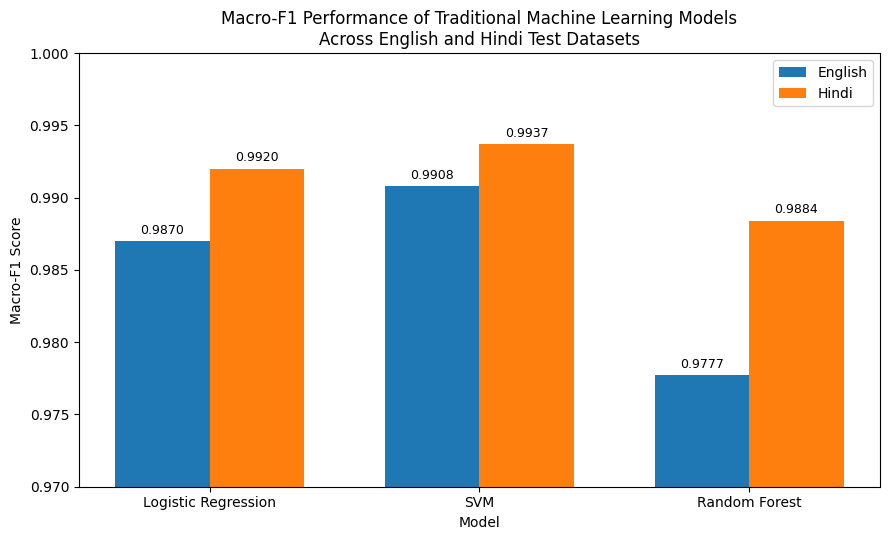

In [ ]:
# Final traditional ML results from your latest output
results = pd.DataFrame({
    "Model": ["Logistic Regression", "SVM", "Random Forest"],
    "English": [0.9870, 0.9908, 0.9777],
    "Hindi": [0.9920, 0.9937, 0.9884]
})

# Bar positions
x = np.arange(len(results["Model"]))
width = 0.35

# Create figure
fig, ax = plt.subplots(figsize=(9, 5.5))

bars1 = ax.bar(
    x - width/2,
    results["English"],
    width,
    label="English"
)

bars2 = ax.bar(
    x + width/2,
    results["Hindi"],
    width,
    label="Hindi"
)

# Axis labels and title
ax.set_xlabel("Model")
ax.set_ylabel("Macro-F1 Score")
ax.set_title(
    "Macro-F1 Performance of Traditional Machine Learning Models\n"
    "Across English and Hindi Test Datasets"
)

ax.set_xticks(x)
ax.set_xticklabels(results["Model"])

# Narrow range so small performance differences are visible
ax.set_ylim(0.97, 1.00)

ax.legend()

# Add exact values above each bar
for bars in [bars1, bars2]:
    for bar in bars:
        height = bar.get_height()
        ax.text(
            bar.get_x() + bar.get_width()/2,
            height + 0.0003,
            f"{height:.4f}",
            ha="center",
            va="bottom",
            fontsize=9
        )

plt.tight_layout()

# Save high-resolution version for dissertation
plt.savefig(
    "Figure_4_1_Traditional_ML_Macro_F1.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

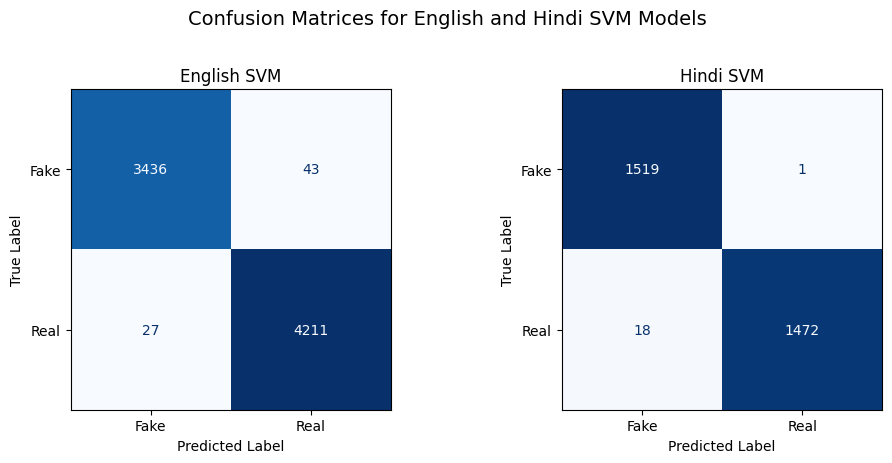

In [ ]:
from sklearn.metrics import ConfusionMatrixDisplay

# Final SVM confusion matrices
cm_english = np.array([
    [3436, 43],
    [27, 4211]
])

cm_hindi = np.array([
    [1519, 1],
    [18, 1472]
])

# Create side-by-side plots
fig, axes = plt.subplots(1, 2, figsize=(10, 4.5))

# English
disp_en = ConfusionMatrixDisplay(
    confusion_matrix=cm_english,
    display_labels=["Fake", "Real"]
)

disp_en.plot(
    ax=axes[0],
    cmap="Blues",
    colorbar=False,
    values_format="d"
)

axes[0].set_title("English SVM")
axes[0].set_xlabel("Predicted Label")
axes[0].set_ylabel("True Label")

# Hindi
disp_hi = ConfusionMatrixDisplay(
    confusion_matrix=cm_hindi,
    display_labels=["Fake", "Real"]
)

disp_hi.plot(
    ax=axes[1],
    cmap="Blues",
    colorbar=False,
    values_format="d"
)

axes[1].set_title("Hindi SVM")
axes[1].set_xlabel("Predicted Label")
axes[1].set_ylabel("True Label")

# Overall title
fig.suptitle(
    "Confusion Matrices for English and Hindi SVM Models",
    fontsize=14,
    y=1.02
)

plt.tight_layout()

# Save high-resolution image
plt.savefig(
    "Figure_4_2_SVM_Confusion_Matrices.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## **9. XLM-RoBERTa Token-Length Analysis**

Before fine-tuning the transformer model, the distribution of tokenised sequence
lengths was examined separately for the English and Hindi training datasets.
XLM-RoBERTa uses subword tokenisation; therefore, the word-count distributions
identified during exploratory analysis cannot directly determine the appropriate
maximum sequence length.

Token-length analysis was conducted using the training data only. The resulting
distribution was used to inform the maximum sequence length adopted during
transformer fine-tuning.

In [ ]:
# XLM-RoBERTa Setup

!pip -q install transformers sentencepiece

from transformers import AutoTokenizer
import numpy as np
import pandas as pd
import time

MODEL_NAME = "FacebookAI/xlm-roberta-base"

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

print("Tokenizer loaded:", MODEL_NAME)
print("Model maximum length:", tokenizer.model_max_length)
print("Vocabulary size:", tokenizer.vocab_size)

Tokenizer loaded: FacebookAI/xlm-roberta-base
Model maximum length: 512
Vocabulary size: 250002


In [ ]:
# XLM-R Token-Length Analysis on training data

def analyse_token_lengths(texts, language):

    lengths = []
    start = time.time()

    texts = texts.astype(str).tolist()

    for i, text in enumerate(texts):

        tokens = tokenizer(
            text,
            add_special_tokens=True,
            truncation=False,
            return_attention_mask=False,
            return_token_type_ids=False
        )

        lengths.append(len(tokens["input_ids"]))

        if (i + 1) % 5000 == 0:
            print(
                f"{language}: processed "
                f"{i + 1:,}/{len(texts):,} documents"
            )

    lengths = np.array(lengths)

    summary = {
        "Language": language,
        "Documents": len(lengths),
        "Mean": np.mean(lengths),
        "Median": np.median(lengths),
        "75th percentile": np.percentile(lengths, 75),
        "90th percentile": np.percentile(lengths, 90),
        "95th percentile": np.percentile(lengths, 95),
        "99th percentile": np.percentile(lengths, 99),
        "Maximum": np.max(lengths),
        "% <= 128": np.mean(lengths <= 128) * 100,
        "% <= 256": np.mean(lengths <= 256) * 100,
        "% <= 384": np.mean(lengths <= 384) * 100,
        "% <= 512": np.mean(lengths <= 512) * 100
    }

    print(
        f"{language} completed in "
        f"{time.time() - start:.2f} seconds."
    )

    return lengths, summary


token_lengths_en, summary_en = analyse_token_lengths(
    X_train_en,
    "English"
)

token_lengths_hi, summary_hi = analyse_token_lengths(
    X_train_hi,
    "Hindi"
)

token_length_summary = pd.DataFrame(
    [summary_en, summary_hi]
)

display(
    token_length_summary.round(2)
)

[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (736 > 512). Running this sequence through the model will result in indexing errors


English: processed 5,000/30,867 documents
English: processed 10,000/30,867 documents
English: processed 15,000/30,867 documents
English: processed 20,000/30,867 documents
English: processed 25,000/30,867 documents
English: processed 30,000/30,867 documents
English completed in 51.99 seconds.
Hindi: processed 5,000/12,039 documents
Hindi: processed 10,000/12,039 documents
Hindi completed in 52.26 seconds.


,Language,Documents,Mean,Median,75th percentile,90th percentile,95th percentile,99th percentile,Maximum,% <= 128,% <= 256,% <= 384,% <= 512
0,English,30867,557.02,507.0,706.0,1016.0,1229.7,1807.00,10982,11.81,21.94,32.80,50.82
1,Hindi,12039,998.34,827.0,1195.5,1979.0,2159.1,2762.72,12470,0.76,2.90,5.62,15.66


In [ ]:
from sklearn.model_selection import train_test_split

# XLM-R Training / Validation Split; Original held-out test sets remain untouched


X_train_en_xlm, X_val_en_xlm, y_train_en_xlm, y_val_en_xlm = train_test_split(
    X_train_en,
    y_train_en,
    test_size=0.10,
    random_state=42,
    stratify=y_train_en
)

X_train_hi_xlm, X_val_hi_xlm, y_train_hi_xlm, y_val_hi_xlm = train_test_split(
    X_train_hi,
    y_train_hi,
    test_size=0.10,
    random_state=42,
    stratify=y_train_hi
)

print("XLM-R DATA SPLITS")
print("=" * 45)

print("\nEnglish")
print("Training:  ", len(X_train_en_xlm))
print("Validation:", len(X_val_en_xlm))
print("Final test:", len(X_test_en))

print("\nHindi")
print("Training:  ", len(X_train_hi_xlm))
print("Validation:", len(X_val_hi_xlm))
print("Final test:", len(X_test_hi))

XLM-R DATA SPLITS

English
Training:   27780
Validation: 3087
Final test: 7717

Hindi
Training:   10835
Validation: 1204
Final test: 3010


In [ ]:
# XLM-RoBERTa Fine-Tuning: Imports and Reproducibility

!pip -q install -U datasets accelerate evaluate sentencepiece

import os
import random
import numpy as np
import pandas as pd
import torch

from datasets import Dataset
from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification,
    DataCollatorWithPadding,
    TrainingArguments,
    Trainer,
    EarlyStoppingCallback,
    set_seed
)

from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support,
    classification_report,
    confusion_matrix
)

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
set_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

print("Seed:", SEED)

CUDA available: True
GPU: NVIDIA L4
Seed: 42


In [ ]:
# XLM-R Configuration

MODEL_NAME = "FacebookAI/xlm-roberta-base"

MAX_LENGTH = 512
LEARNING_RATE = 2e-5
NUM_EPOCHS = 3
WEIGHT_DECAY = 0.01

TRAIN_BATCH_SIZE = 4
EVAL_BATCH_SIZE = 8

GRADIENT_ACCUMULATION_STEPS = 4

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

print("Model:", MODEL_NAME)
print("Maximum sequence length:", MAX_LENGTH)
print("Learning rate:", LEARNING_RATE)
print("Epochs:", NUM_EPOCHS)
print("Training batch size:", TRAIN_BATCH_SIZE)
print("Gradient accumulation:", GRADIENT_ACCUMULATION_STEPS)
print(
    "Effective training batch size:",
    TRAIN_BATCH_SIZE * GRADIENT_ACCUMULATION_STEPS
)

Model: FacebookAI/xlm-roberta-base
Maximum sequence length: 512
Learning rate: 2e-05
Epochs: 3
Training batch size: 4
Gradient accumulation: 4
Effective training batch size: 16


In [ ]:
# Convert Existing Splits to Hugging Face Datasets

def create_hf_dataset(texts, labels):

    temp_df = pd.DataFrame({
        "text": texts.astype(str).tolist(),
        "label": labels.astype(int).tolist()
    })

    return Dataset.from_pandas(
        temp_df,
        preserve_index=False
    )


# English
train_dataset_en = create_hf_dataset(
    X_train_en_xlm,
    y_train_en_xlm
)

val_dataset_en = create_hf_dataset(
    X_val_en_xlm,
    y_val_en_xlm
)

test_dataset_en = create_hf_dataset(
    X_test_en,
    y_test_en
)


# Hindi
train_dataset_hi = create_hf_dataset(
    X_train_hi_xlm,
    y_train_hi_xlm
)

val_dataset_hi = create_hf_dataset(
    X_val_hi_xlm,
    y_val_hi_xlm
)

test_dataset_hi = create_hf_dataset(
    X_test_hi,
    y_test_hi
)


print("ENGLISH")
print("Train:", len(train_dataset_en))
print("Validation:", len(val_dataset_en))
print("Test:", len(test_dataset_en))

print("\nHINDI")
print("Train:", len(train_dataset_hi))
print("Validation:", len(val_dataset_hi))
print("Test:", len(test_dataset_hi))

ENGLISH
Train: 27780
Validation: 3087
Test: 7717

HINDI
Train: 10835
Validation: 1204
Test: 3010


In [ ]:
# XLM-R Tokenisation

def tokenize_function(batch):

    return tokenizer(
        batch["text"],
        truncation=True,
        max_length=MAX_LENGTH,
        padding=False
    )


def tokenize_dataset(dataset, description):

    print(f"Tokenising {description}...")

    tokenized = dataset.map(
        tokenize_function,
        batched=True,
        remove_columns=["text"]
    )

    print(f"{description}: {len(tokenized):,} observations")

    return tokenized


# English
tokenized_train_en = tokenize_dataset(
    train_dataset_en,
    "English training"
)

tokenized_val_en = tokenize_dataset(
    val_dataset_en,
    "English validation"
)

tokenized_test_en = tokenize_dataset(
    test_dataset_en,
    "English test"
)


# Hindi
tokenized_train_hi = tokenize_dataset(
    train_dataset_hi,
    "Hindi training"
)

tokenized_val_hi = tokenize_dataset(
    val_dataset_hi,
    "Hindi validation"
)

tokenized_test_hi = tokenize_dataset(
    test_dataset_hi,
    "Hindi test"
)

Tokenising English training...


Map:   0%|          | 0/27780 [00:00<?, ? examples/s]

English training: 27,780 observations
Tokenising English validation...


Map:   0%|          | 0/3087 [00:00<?, ? examples/s]

English validation: 3,087 observations
Tokenising English test...


Map:   0%|          | 0/7717 [00:00<?, ? examples/s]

... (3 outputs left out)

Map:   0%|          | 0/1204 [00:00<?, ? examples/s]

Hindi validation: 1,204 observations
Tokenising Hindi test...


Map:   0%|          | 0/3010 [00:00<?, ? examples/s]

Hindi test: 3,010 observations


In [ ]:
# Dynamic padding within each batch
data_collator = DataCollatorWithPadding(
    tokenizer=tokenizer,
    padding=True
)

print("Tokenisation complete.")

Tokenisation complete.


In [ ]:
# Evaluation Metrics; with Macro-F1 being the primary metric

def compute_metrics(eval_pred):

    logits, labels = eval_pred
    predictions = np.argmax(logits, axis=-1)

    accuracy = accuracy_score(
        labels,
        predictions
    )

    precision, recall, f1, _ = precision_recall_fscore_support(
        labels,
        predictions,
        average="macro",
        zero_division=0
    )

    return {
        "accuracy": accuracy,
        "precision_macro": precision,
        "recall_macro": recall,
        "f1_macro": f1
    }

In [ ]:
# XLM-R Binary Classification Model

id2label = {
    0: "Fake",
    1: "Real"
}

label2id = {
    "Fake": 0,
    "Real": 1
}


def initialise_xlmr_model():

    model = AutoModelForSequenceClassification.from_pretrained(
        MODEL_NAME,
        num_labels=2,
        id2label=id2label,
        label2id=label2id
    )

    return model

In [ ]:
# XLM-R Training Function

def train_xlmr(
    train_dataset,
    val_dataset,
    output_dir
):

    model = initialise_xlmr_model()

    training_args = TrainingArguments(
        output_dir=output_dir,

        learning_rate=LEARNING_RATE,

        per_device_train_batch_size=TRAIN_BATCH_SIZE,
        per_device_eval_batch_size=EVAL_BATCH_SIZE,

        gradient_accumulation_steps=GRADIENT_ACCUMULATION_STEPS,

        num_train_epochs=NUM_EPOCHS,
        weight_decay=WEIGHT_DECAY,

        eval_strategy="epoch",
        save_strategy="epoch",

        load_best_model_at_end=True,
        metric_for_best_model="f1_macro",
        greater_is_better=True,

        save_total_limit=2,

        logging_strategy="steps",
        logging_steps=250,

        fp16=torch.cuda.is_available(),

        seed=SEED,
        data_seed=SEED,

        report_to="none"
    )

    trainer = Trainer(
        model=model,
        args=training_args,

        train_dataset=train_dataset,
        eval_dataset=val_dataset,

        data_collator=data_collator,
        compute_metrics=compute_metrics,

        callbacks=[
            EarlyStoppingCallback(
                early_stopping_patience=1
            )
        ]
    )

    trainer.train()

    return trainer

In [ ]:
# Fine-tune XLM-R: ENGLISH

trainer_en = train_xlmr(
    tokenized_train_en,
    tokenized_val_en,
    "./xlmr_english"
)

model.safetensors: reconstructing file:   0%|          |  0.00B / 1.12GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] XLMRobertaForSequenceClassification LOAD REPORT from: FacebookAI/xlm-roberta-base
Key                         | Status     | 
----------------------------+------------+-
lm_head.layer_norm.bias     | UNEXPECTED | 
lm_head.dense.weight        | UNEXPECTED | 
roberta.pooler.dense.weight | UNEXPECTED | 
lm_head.bias                | UNEXPECTED | 
roberta.pooler.dense.bias   | UNEXPECTED | 
lm_head.layer_norm.weight   | UNEXPECTED | 
lm_head.dense.bias          | UNEXPECTED | 
classifier.out_proj.bias    | MISSING    | 
classifier.out_proj.weight  | MISSING    | 
classifier.dense.bias       | MISSING    | 
classifier.dense.weight     | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Epoch,Training Loss,Validation Loss,Accuracy,Precision Macro,Recall Macro,F1 Macro
1,0.076783,0.034575,0.995789,0.996194,0.995330,0.995744
2,0.035543,0.004277,0.998704,0.998823,0.998563,0.998691
3,0.000012,0.002888,0.999352,0.999411,0.999282,0.999346


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

In [ ]:

# Confirm Best English XLM-R Checkpoint

print("Best checkpoint:", trainer_en.state.best_model_checkpoint)
print("Best validation metric:", trainer_en.state.best_metric)
print("Completed epochs:", trainer_en.state.epoch)

english_val_metrics = trainer_en.evaluate(
    tokenized_val_en
)

print("\nENGLISH VALIDATION METRICS")
print("=" * 45)

for key, value in english_val_metrics.items():
    if isinstance(value, float):
        print(f"{key}: {value:.6f}")

Best checkpoint: ./xlmr_english/checkpoint-5211
Best validation metric: 0.9993457350487636
Completed epochs: 3.0


Training Loss,Validation Loss,Epoch,Accuracy,Precision Macro,Recall Macro,F1 Macro
0.000012,0.002888,3,0.999352,0.999411,0.999282,0.999346



ENGLISH VALIDATION METRICS
eval_loss: 0.002888
eval_accuracy: 0.999352
eval_precision_macro: 0.999411
eval_recall_macro: 0.999282
eval_f1_macro: 0.999346


In [ ]:
# Save Best English Model

ENGLISH_MODEL_PATH = "/content/drive/MyDrive/Colab Notebooks/Dissertation/xlmr_english_best"

trainer_en.save_model(ENGLISH_MODEL_PATH)
tokenizer.save_pretrained(ENGLISH_MODEL_PATH)

print("English model saved to:", ENGLISH_MODEL_PATH)

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

English model saved to: /content/drive/MyDrive/Colab Notebooks/Dissertation/xlmr_english_best


In [ ]:

# Fine-tune XLM-R: HINDI

# Release English model GPU memory before loading Hindi model
import gc

trainer_en.model.to("cpu")
gc.collect()

if torch.cuda.is_available():
    torch.cuda.empty_cache()

# Train independently from the pretrained XLM-R checkpoint
trainer_hi = train_xlmr(
    tokenized_train_hi,
    tokenized_val_hi,
    "./xlmr_hindi"
)

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] XLMRobertaForSequenceClassification LOAD REPORT from: FacebookAI/xlm-roberta-base
Key                         | Status     | 
----------------------------+------------+-
lm_head.layer_norm.bias     | UNEXPECTED | 
lm_head.dense.weight        | UNEXPECTED | 
roberta.pooler.dense.weight | UNEXPECTED | 
lm_head.bias                | UNEXPECTED | 
roberta.pooler.dense.bias   | UNEXPECTED | 
lm_head.layer_norm.weight   | UNEXPECTED | 
lm_head.dense.bias          | UNEXPECTED | 
classifier.out_proj.bias    | MISSING    | 
classifier.out_proj.weight  | MISSING    | 
classifier.dense.bias       | MISSING    | 
classifier.dense.weight     | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Epoch,Training Loss,Validation Loss,Accuracy,Precision Macro,Recall Macro,F1 Macro
1,0.319056,0.025593,0.994186,0.994179,0.994227,0.994186
2,0.078920,0.018056,0.996678,0.996677,0.996677,0.996677
3,0.040266,0.030688,0.994186,0.994195,0.994177,0.994185


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

In [ ]:
# Confirm Best Hindi XLM-R Checkpoint

print("Best checkpoint:", trainer_hi.state.best_model_checkpoint)
print("Best validation metric:", trainer_hi.state.best_metric)
print("Completed epochs:", trainer_hi.state.epoch)

hindi_val_metrics = trainer_hi.evaluate(tokenized_val_hi)

print("\nHINDI VALIDATION METRICS")
print("=" * 45)

for key, value in hindi_val_metrics.items():
    if isinstance(value, float):
        print(f"{key}: {value:.6f}")

Best checkpoint: ./xlmr_hindi/checkpoint-1356
Best validation metric: 0.9966774108089014
Completed epochs: 3.0


Training Loss,Validation Loss,Epoch,Accuracy,Precision Macro,Recall Macro,F1 Macro
0.040266,0.018056,3,0.996678,0.996677,0.996677,0.996677



HINDI VALIDATION METRICS
eval_loss: 0.018056
eval_accuracy: 0.996678
eval_precision_macro: 0.996677
eval_recall_macro: 0.996677
eval_f1_macro: 0.996677


In [ ]:
# Save Best Hindi Model

HINDI_MODEL_PATH = "/content/drive/MyDrive/Colab Notebooks/Dissertation/xlmr_hindi_best"

trainer_hi.save_model(HINDI_MODEL_PATH)
tokenizer.save_pretrained(HINDI_MODEL_PATH)

print("Hindi model saved to:", HINDI_MODEL_PATH)

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Hindi model saved to: /content/drive/MyDrive/Colab Notebooks/Dissertation/xlmr_hindi_best


In [ ]:
BASE_DIR = "/content/drive/MyDrive/Colab Notebooks/Dissertation"

ENGLISH_MODEL_PATH = f"{BASE_DIR}/xlmr_english_best"
HINDI_MODEL_PATH = f"{BASE_DIR}/xlmr_hindi_best"

trainer_en.save_model(ENGLISH_MODEL_PATH)
trainer_hi.save_model(HINDI_MODEL_PATH)

tokenizer.save_pretrained(ENGLISH_MODEL_PATH)
tokenizer.save_pretrained(HINDI_MODEL_PATH)

print("Both models saved successfully.")

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Both models saved successfully.


In [ ]:
print("ENGLISH")
print("Best checkpoint:", trainer_en.state.best_model_checkpoint)
print("Best Macro-F1:", trainer_en.state.best_metric)

print("\nHINDI")
print("Best checkpoint:", trainer_hi.state.best_model_checkpoint)
print("Best Macro-F1:", trainer_hi.state.best_metric)

ENGLISH
Best checkpoint: ./xlmr_english/checkpoint-5211
Best Macro-F1: 0.9993457350487636

HINDI
Best checkpoint: ./xlmr_hindi/checkpoint-1356
Best Macro-F1: 0.9966774108089014


In [ ]:
print("English test:", len(X_test_en))
print("Hindi test:", len(X_test_hi))

print("English tokenised test:", len(tokenized_test_en))
print("Hindi tokenised test:", len(tokenized_test_hi))

assert len(X_test_en) == 7717
assert len(X_test_hi) == 3010

assert len(tokenized_test_en) == 7717
assert len(tokenized_test_hi) == 3010

print("All test-set checks passed.")

English test: 7717
Hindi test: 3010
English tokenised test: 7717
Hindi tokenised test: 3010
All test-set checks passed.


In [ ]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

def evaluate_xlmr_predictions(y_true, y_pred, language):

    results = {
        "Language": language,
        "Model": "XLM-R",
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision_Macro": precision_score(
            y_true, y_pred, average="macro", zero_division=0
        ),
        "Recall_Macro": recall_score(
            y_true, y_pred, average="macro", zero_division=0
        ),
        "F1_Macro": f1_score(
            y_true, y_pred, average="macro", zero_division=0
        )
    }

    print(f"\n{language.upper()} XLM-R TEST RESULTS")
    print("=" * 50)

    display(pd.DataFrame([results]).round(4))

    print("\nClassification report:")
    print(
        classification_report(
            y_true,
            y_pred,
            labels=[0, 1],
            target_names=["Fake", "Real"],
            zero_division=0
        )
    )

    print("\nConfusion matrix:")
    print(
        confusion_matrix(
            y_true,
            y_pred,
            labels=[0, 1]
        )
    )

    return results

In [ ]:
from torch.utils.data import DataLoader
from transformers import DataCollatorWithPadding

def predict_saved_xlmr(model_path, tokenized_test_dataset, batch_size=4):

    device = torch.device(
        "cuda" if torch.cuda.is_available() else "cpu"
    )

    print("Using device:", device)

    model = AutoModelForSequenceClassification.from_pretrained(
        model_path,
        local_files_only=True
    ).to(device)

    model.eval()

    local_tokenizer = AutoTokenizer.from_pretrained(
        model_path,
        local_files_only=True
    )

    collator = DataCollatorWithPadding(
        tokenizer=local_tokenizer,
        return_tensors="pt"
    )

    loader = DataLoader(
        tokenized_test_dataset,
        batch_size=batch_size,
        shuffle=False,
        collate_fn=collator
    )

    predictions = []

    with torch.inference_mode():

        for batch in loader:

            batch = {
                key: value.to(device)
                for key, value in batch.items()
                if key != "labels"
            }

            outputs = model(**batch)

            batch_predictions = torch.argmax(
                outputs.logits,
                dim=-1
            )

            predictions.extend(
                batch_predictions.cpu().numpy().tolist()
            )

    del model
    gc.collect()

    if torch.cuda.is_available():
        torch.cuda.empty_cache()

    return np.array(predictions)

In [ ]:
# English held-out test predictions
y_pred_xlmr_en = predict_saved_xlmr(
    ENGLISH_MODEL_PATH,
    tokenized_test_en,
    batch_size=4
)

xlmr_results_en = evaluate_xlmr_predictions(
    y_test_en.to_numpy(),
    y_pred_xlmr_en,
    "English"
)

Using device: cuda


Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]


ENGLISH XLM-R TEST RESULTS


,Language,Model,Accuracy,Precision_Macro,Recall_Macro,F1_Macro
0,English,XLM-R,0.9995,0.9995,0.9995,0.9995



Classification report:
              precision    recall  f1-score   support

        Fake       1.00      1.00      1.00      3479
        Real       1.00      1.00      1.00      4238

    accuracy                           1.00      7717
   macro avg       1.00      1.00      1.00      7717
weighted avg       1.00      1.00      1.00      7717


Confusion matrix:
[[3476    3]
 [   1 4237]]


In [ ]:
# Hindi held-out test predictions
y_pred_xlmr_hi = predict_saved_xlmr(
    HINDI_MODEL_PATH,
    tokenized_test_hi,
    batch_size=4
)

xlmr_results_hi = evaluate_xlmr_predictions(
    y_test_hi.to_numpy(),
    y_pred_xlmr_hi,
    "Hindi"
)

Using device: cuda


Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]


HINDI XLM-R TEST RESULTS


,Language,Model,Accuracy,Precision_Macro,Recall_Macro,F1_Macro
0,Hindi,XLM-R,0.9947,0.9947,0.9947,0.9947



Classification report:
              precision    recall  f1-score   support

        Fake       0.99      1.00      0.99      1520
        Real       1.00      0.99      0.99      1490

    accuracy                           0.99      3010
   macro avg       0.99      0.99      0.99      3010
weighted avg       0.99      0.99      0.99      3010


Confusion matrix:
[[1514    6]
 [  10 1480]]


In [ ]:
xlmr_results_df = pd.DataFrame([
    xlmr_results_en,
    xlmr_results_hi
])

display(xlmr_results_df.round(4))

xlmr_results_df.to_csv(
    f"{BASE_DIR}/xlmr_final_test_results.csv",
    index=False
)

np.save(
    f"{BASE_DIR}/xlmr_english_test_predictions.npy",
    y_pred_xlmr_en
)

np.save(
    f"{BASE_DIR}/xlmr_hindi_test_predictions.npy",
    y_pred_xlmr_hi
)

print("Results and predictions saved to Google Drive.")

,Language,Model,Accuracy,Precision_Macro,Recall_Macro,F1_Macro
0,English,XLM-R,0.9995,0.9995,0.9995,0.9995
1,Hindi,XLM-R,0.9947,0.9947,0.9947,0.9947


Results and predictions saved to Google Drive.


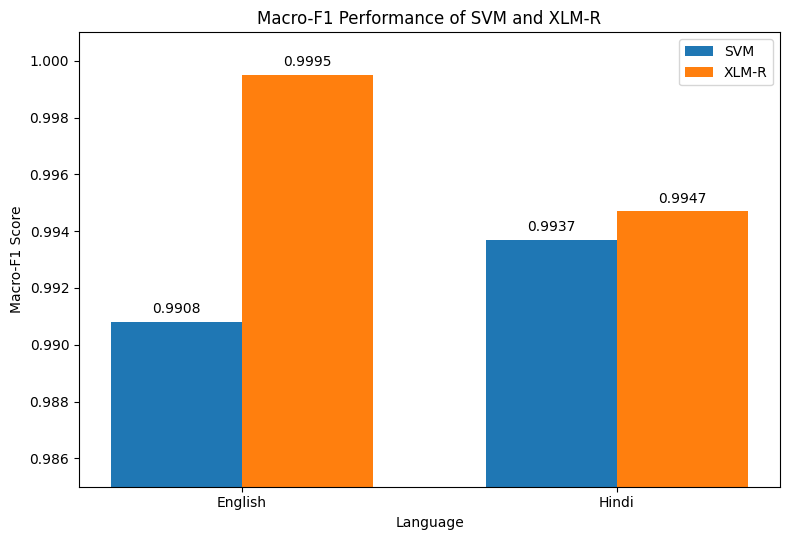

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# Final Macro-F1 scores
languages = ["English", "Hindi"]

svm_scores = [0.9908, 0.9937]
xlmr_scores = [0.9995, 0.9947]

x = np.arange(len(languages))
width = 0.35

fig, ax = plt.subplots(figsize=(8, 5.5))

bars1 = ax.bar(
    x - width/2,
    svm_scores,
    width,
    label="SVM"
)

bars2 = ax.bar(
    x + width/2,
    xlmr_scores,
    width,
    label="XLM-R"
)

ax.set_xlabel("Language")
ax.set_ylabel("Macro-F1 Score")
ax.set_title("Macro-F1 Performance of SVM and XLM-R")

ax.set_xticks(x)
ax.set_xticklabels(languages)

# Narrow range because all scores are very high
ax.set_ylim(0.985, 1.001)

ax.legend()

# Add exact values above bars
for bars in [bars1, bars2]:
    for bar in bars:
        height = bar.get_height()
        ax.text(
            bar.get_x() + bar.get_width()/2,
            height + 0.0002,
            f"{height:.4f}",
            ha="center",
            va="bottom",
            fontsize=10
        )

plt.tight_layout()

plt.savefig(
    "Figure_4_3_SVM_vs_XLMR_Macro_F1.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## **10. Explainable Artificial Intelligence (XAI)**



In [ ]:
# Save Traditional ML Models for XAI

import os
import joblib

XAI_DIR = os.path.join(BASE_DIR, "xai_models")
os.makedirs(XAI_DIR, exist_ok=True)

svm_en = searches_en["SVM"].best_estimator_
svm_hi = searches_hi["SVM"].best_estimator_

joblib.dump(svm_en, f"{XAI_DIR}/svm_english.joblib")
joblib.dump(svm_hi, f"{XAI_DIR}/svm_hindi.joblib")

joblib.dump(tfidf_en, f"{XAI_DIR}/tfidf_english.joblib")
joblib.dump(tfidf_hi, f"{XAI_DIR}/tfidf_hindi.joblib")

print("English SVM C:", svm_en.C)
print("Hindi SVM C:", svm_hi.C)

print("English vocabulary:", len(tfidf_en.vocabulary_))
print("Hindi vocabulary:", len(tfidf_hi.vocabulary_))

print("\nAll four objects saved to:", XAI_DIR)

English SVM C: 1.0
Hindi SVM C: 2.0
English vocabulary: 20000
Hindi vocabulary: 20000

All four objects saved to: /content/drive/MyDrive/Colab Notebooks/Dissertation/xai_models


In [ ]:
# Select Test Observations for XAI

def select_xai_examples(texts, labels, predictions, language):
    df = pd.DataFrame({
        "text": texts.astype(str).tolist(),
        "true_label": np.asarray(labels),
        "predicted_label": np.asarray(predictions)
    })

    df["outcome"] = np.select(
        [
            (df.true_label == 0) & (df.predicted_label == 0),
            (df.true_label == 1) & (df.predicted_label == 1),
            (df.true_label != df.predicted_label)
        ],
        ["Correct Fake", "Correct Real", "Misclassified"],
        default="Other"
    )

    selected = []

    for outcome in [
        "Correct Fake",
        "Correct Real",
        "Misclassified"
    ]:
        subset = df[df["outcome"] == outcome]

        if len(subset):
            selected.append(
                subset.sample(
                    n=min(2, len(subset)),
                    random_state=42
                )
            )

    result = pd.concat(selected).sort_index()
    result["Language"] = language
    result["test_index"] = result.index

    return result


xai_examples_en = select_xai_examples(
    X_test_en,
    y_test_en,
    y_pred_xlmr_en,
    "English"
)

xai_examples_hi = select_xai_examples(
    X_test_hi,
    y_test_hi,
    y_pred_xlmr_hi,
    "Hindi"
)

print("ENGLISH EXAMPLES")
display(
    xai_examples_en[
        ["test_index", "true_label", "predicted_label", "outcome"]
    ]
)

print("\nHINDI EXAMPLES")
display(
    xai_examples_hi[
        ["test_index", "true_label", "predicted_label", "outcome"]
    ]
)

ENGLISH EXAMPLES


,test_index,true_label,predicted_label,outcome
1428,1428,1,1,Correct Real
3025,3025,0,1,Misclassified
3174,3174,0,0,Correct Fake
4602,4602,0,0,Correct Fake
5834,5834,1,1,Correct Real
6703,6703,1,0,Misclassified



HINDI EXAMPLES


,test_index,true_label,predicted_label,outcome
25,25,1,0,Misclassified
121,121,0,0,Correct Fake
201,201,0,1,Misclassified
366,366,0,0,Correct Fake
542,542,1,1,Correct Real
1323,1323,1,1,Correct Real


In [ ]:
xai_examples_en.to_csv(
    f"{BASE_DIR}/xai_examples_english.csv",
    index=False
)

xai_examples_hi.to_csv(
    f"{BASE_DIR}/xai_examples_hindi.csv",
    index=False
)

print("XAI observation samples saved.")

XAI observation samples saved.


In [ ]:
# XAI — SVM Predictions for Selected Test Articles

def add_svm_predictions(examples, vectorizer, model):
    result = examples.copy()

    X_selected = vectorizer.transform(
        result["text"].astype(str).tolist()
    )

    result["svm_prediction"] = model.predict(X_selected)
    result["svm_decision_score"] = model.decision_function(X_selected)

    result["svm_outcome"] = np.where(
        result["true_label"] == result["svm_prediction"],
        "Correct",
        "Misclassified"
    )

    return result


xai_examples_en = add_svm_predictions(
    xai_examples_en, tfidf_en, svm_en
)

xai_examples_hi = add_svm_predictions(
    xai_examples_hi, tfidf_hi, svm_hi
)

columns = [
    "test_index",
    "true_label",
    "predicted_label",
    "svm_prediction",
    "outcome",
    "svm_outcome"
]

print("ENGLISH")
display(xai_examples_en[columns])

print("\nHINDI")
display(xai_examples_hi[columns])

ENGLISH


,test_index,true_label,predicted_label,svm_prediction,outcome,svm_outcome
1428,1428,1,1,1,Correct Real,Correct
3025,3025,0,1,0,Misclassified,Correct
3174,3174,0,0,0,Correct Fake,Correct
4602,4602,0,0,0,Correct Fake,Correct
5834,5834,1,1,1,Correct Real,Correct
6703,6703,1,0,1,Misclassified,Correct



HINDI


,test_index,true_label,predicted_label,svm_prediction,outcome,svm_outcome
25,25,1,0,0,Misclassified,Misclassified
121,121,0,0,0,Correct Fake,Correct
201,201,0,1,0,Misclassified,Correct
366,366,0,0,0,Correct Fake,Correct
542,542,1,1,1,Correct Real,Correct
1323,1323,1,1,1,Correct Real,Correct


### **10.1. LIME Analysis**

In [ ]:

!pip -q install lime

from lime.lime_text import LimeTextExplainer
from scipy.special import expit

CLASS_NAMES = ["Fake", "Real"]


def make_svm_lime_predictor(vectorizer, model):

    def predict_fn(texts):

        features = vectorizer.transform(list(texts))

        scores = model.decision_function(features)

        real_scores = expit(scores)
        fake_scores = 1 - real_scores

        return np.column_stack([
            fake_scores,
            real_scores
        ])

    return predict_fn


predict_svm_en = make_svm_lime_predictor(
    tfidf_en, svm_en
)

predict_svm_hi = make_svm_lime_predictor(
    tfidf_hi, svm_hi
)


lime_en = LimeTextExplainer(
    class_names=CLASS_NAMES,
    split_expression=r"\s+",
    bow=True,
    random_state=42
)

lime_hi = LimeTextExplainer(
    class_names=CLASS_NAMES,
    split_expression=r"\s+",
    bow=True,
    random_state=42
)

print("English and Hindi LIME explainers ready.")

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 275.7/275.7 kB 9.0 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
English and Hindi LIME explainers ready.


In [ ]:
# XAI — First LIME Explanations

english_example = xai_examples_en[
    xai_examples_en["outcome"] == "Correct Fake"
].iloc[0]

hindi_example = xai_examples_hi[
    xai_examples_hi["outcome"] == "Correct Fake"
].iloc[0]


exp_en = lime_en.explain_instance(
    english_example["text"],
    predict_svm_en,
    labels=[0, 1],
    num_features=15,
    num_samples=1000
)

exp_hi = lime_hi.explain_instance(
    hindi_example["text"],
    predict_svm_hi,
    labels=[0, 1],
    num_features=15,
    num_samples=1000
)


print("ENGLISH — TEST INDEX:", english_example["test_index"])
print("SVM prediction:", CLASS_NAMES[int(english_example["svm_prediction"])])

display(
    exp_en.as_list(
        label=int(english_example["svm_prediction"])
    )
)

print("\nHINDI — TEST INDEX:", hindi_example["test_index"])
print("SVM prediction:", CLASS_NAMES[int(hindi_example["svm_prediction"])])

display(
    exp_hi.as_list(
        label=int(hindi_example["svm_prediction"])
    )
)

ENGLISH — TEST INDEX: 3174
SVM prediction: Fake


[(np.str_('said'), -0.051635134743153455),
 (np.str_('the'), 0.046984883205612615),
 (np.str_('via'), 0.041718505319192294),
 (np.str_('Fox'), 0.02604499366745773),
 (np.str_('had'), -0.02348572624451829),
 (np.str_('stated'), 0.018342149379231606),
 (np.str_('just'), 0.017754552676114345),
 (np.str_('on'), -0.017493094219621245),
 (np.str_('that'), 0.015823448305117387),
 (np.str_('reports'), 0.01566136173898199),
 (np.str_('story'), 0.014230397500693215),
 (np.str_('Image'), 0.013699725250416489),
 (np.str_('officer'), 0.0099419869020026),
 (np.str_('Huffington'), 0.0064598479834746935),
 (np.str_('this'), 0.005526784229882436)]


HINDI — TEST INDEX: 121
SVM prediction: Fake


[(np.str_('शानदार'), 0.022757584801787207),
 (np.str_('जल्दबाजी'), 0.018915752325323297),
 (np.str_('इन'), 0.01889186068277228),
 (np.str_('करें'), 0.013322377085204387),
 (np.str_('नजर'), 0.012655319636876649),
 (np.str_('नहीं'), -0.008437228911041178),
 (np.str_('कई'), 0.005225827347286897),
 (np.str_('एक्साइटेड'), 0.0044788130383850815),
 (np.str_('यह'), -0.0034077831505581963),
 (np.str_('क्राइम'), -0.002982187277322611),
 (np.str_('सोशल'), -0.0024387287063222696),
 (np.str_('पर'), -0.0014362166761258126),
 (np.str_('वायरल'), 0.0008554449593507129),
 (np.str_('वायरल,'), 0.0005575224104365673),
 (np.str_('खबर'), 0.00032730936501907347)]

In [ ]:
# Save Initial LIME Explanations

XAI_OUTPUT_DIR = os.path.join(BASE_DIR, "xai_outputs")
os.makedirs(XAI_OUTPUT_DIR, exist_ok=True)

exp_en.save_to_file(
    f"{XAI_OUTPUT_DIR}/lime_svm_english_3174.html"
)

exp_hi.save_to_file(
    f"{XAI_OUTPUT_DIR}/lime_svm_hindi_121.html"
)

def lime_to_dataframe(explanation, predicted_label):
    return pd.DataFrame(
        explanation.as_list(label=int(predicted_label)),
        columns=["Feature", "LIME_Weight"]
    )

lime_en_df = lime_to_dataframe(
    exp_en,
    english_example["svm_prediction"]
)

lime_hi_df = lime_to_dataframe(
    exp_hi,
    hindi_example["svm_prediction"]
)

lime_en_df.to_csv(
    f"{XAI_OUTPUT_DIR}/lime_svm_english_3174.csv",
    index=False
)

lime_hi_df.to_csv(
    f"{XAI_OUTPUT_DIR}/lime_svm_hindi_121.csv",
    index=False
)

print("Initial LIME explanations saved.")

Initial LIME explanations saved.


### **10.2. SHAP Analysis**

In [ ]:
!pip -q install shap

import shap

X_train_tfidf_en = tfidf_en.transform(
    X_train_en.astype(str)
)

X_train_tfidf_hi = tfidf_hi.transform(
    X_train_hi.astype(str)
)

X_xai_tfidf_en = tfidf_en.transform(
    xai_examples_en["text"].astype(str)
)

X_xai_tfidf_hi = tfidf_hi.transform(
    xai_examples_hi["text"].astype(str)
)

print("English explanation matrix:", X_xai_tfidf_en.shape)
print("Hindi explanation matrix:", X_xai_tfidf_hi.shape)

English explanation matrix: (6, 20000)
Hindi explanation matrix: (6, 20000)


In [ ]:
# SHAP — Create Language-Specific Explainers

rng = np.random.default_rng(42)

background_en_idx = rng.choice(
    X_train_tfidf_en.shape[0],
    size=min(100, X_train_tfidf_en.shape[0]),
    replace=False
)

background_hi_idx = rng.choice(
    X_train_tfidf_hi.shape[0],
    size=min(100, X_train_tfidf_hi.shape[0]),
    replace=False
)

background_en = X_train_tfidf_en[background_en_idx]
background_hi = X_train_tfidf_hi[background_hi_idx]

explainer_svm_en = shap.LinearExplainer(
    svm_en,
    background_en
)

explainer_svm_hi = shap.LinearExplainer(
    svm_hi,
    background_hi
)

print("English and Hindi SHAP explainers ready.")

English and Hindi SHAP explainers ready.


In [ ]:
# SHAP — Explain Selected Test Articles

shap_values_en = explainer_svm_en(
    X_xai_tfidf_en
)

shap_values_hi = explainer_svm_hi(
    X_xai_tfidf_hi
)

print("English SHAP shape:", shap_values_en.values.shape)
print("Hindi SHAP shape:", shap_values_hi.values.shape)

English SHAP shape: (6, 20000)
Hindi SHAP shape: (6, 20000)


In [ ]:
# SHAP — Extract Top Features for Selected Articles

def extract_shap_features(
    shap_values,
    examples,
    vectorizer,
    language,
    top_n=15
):
    feature_names = vectorizer.get_feature_names_out()
    records = []

    assert len(examples) == shap_values.values.shape[0]

    for position, (_, article) in enumerate(examples.iterrows()):

        predicted_class = int(article["svm_prediction"])
        values = np.asarray(shap_values.values[position]).ravel()

        # LinearSVC positive decision score = Real (label 1).
        # Reverse the sign for Fake so positive means support
        # for the class actually predicted.
        class_support = (
            values if predicted_class == 1 else -values
        )

        top_indices = np.argsort(
            np.abs(class_support)
        )[-top_n:][::-1]

        for rank, feature_idx in enumerate(top_indices, start=1):

            contribution = float(class_support[feature_idx])

            records.append({
                "Language": language,
                "test_index": int(article["test_index"]),
                "true_label": int(article["true_label"]),
                "svm_prediction": predicted_class,
                "feature_rank": rank,
                "feature": feature_names[feature_idx],
                "raw_shap_value": float(values[feature_idx]),
                "predicted_class_support": contribution,
                "direction": (
                    "Supports prediction"
                    if contribution > 0
                    else "Opposes prediction"
                    if contribution < 0
                    else "Neutral"
                )
            })

    return pd.DataFrame(records)


shap_features_en = extract_shap_features(
    shap_values_en,
    xai_examples_en,
    tfidf_en,
    "English"
)

shap_features_hi = extract_shap_features(
    shap_values_hi,
    xai_examples_hi,
    tfidf_hi,
    "Hindi"
)

print("ENGLISH — TEST INDEX 3174")
display(
    shap_features_en[
        shap_features_en["test_index"] == 3174
    ]
)

print("\nHINDI — TEST INDEX 121")
display(
    shap_features_hi[
        shap_features_hi["test_index"] == 121
    ]
)

ENGLISH — TEST INDEX 3174


,Language,test_index,true_label,svm_prediction,feature_rank,feature,raw_shap_value,predicted_class_support,direction
30,English,3174,0,0,1,via,-0.136581,0.136581,Supports prediction
31,English,3174,0,0,2,fox,-0.125491,0.125491,Supports prediction
32,English,3174,0,0,3,stated,-0.073509,0.073509,Supports prediction
33,English,3174,0,0,4,here,-0.072185,0.072185,Supports prediction
34,English,3174,0,0,5,story,-0.061731,0.061731,Supports prediction
35,English,3174,0,0,6,the home,-0.060762,0.060762,Supports prediction
36,English,3174,0,0,7,the officer,-0.057892,0.057892,Supports prediction
37,English,3174,0,0,8,doesn,-0.055123,0.055123,Supports prediction
38,English,3174,0,0,9,that the,-0.051758,0.051758,Supports prediction
39,English,3174,0,0,10,had,0.050235,-0.050235,Opposes prediction



HINDI — TEST INDEX 121


,Language,test_index,true_label,svm_prediction,feature_rank,feature,raw_shap_value,predicted_class_support,direction
15,Hindi,121,0,0,1,खबर,0.043523,-0.043523,Opposes prediction
16,Hindi,121,0,0,2,गय,-0.037088,0.037088,Supports prediction
17,Hindi,121,0,0,3,एनस,-0.034616,0.034616,Supports prediction
18,Hindi,121,0,0,4,नद,-0.032949,0.032949,Supports prediction
19,Hindi,121,0,0,5,बर,0.032512,-0.032512,Opposes prediction
20,Hindi,121,0,0,6,एक टर,-0.028809,0.028809,Supports prediction
21,Hindi,121,0,0,7,सफ,0.028795,-0.028795,Opposes prediction
22,Hindi,121,0,0,8,तस,-0.028287,0.028287,Supports prediction
23,Hindi,121,0,0,9,टब,0.027532,-0.027532,Opposes prediction
24,Hindi,121,0,0,10,उप,-0.025868,0.025868,Supports prediction


In [ ]:
import glob
# Install fonts if necessary
!apt-get -qq install fonts-noto-core

# Find available Devanagari font files
font_paths = glob.glob(
    "/usr/share/fonts/**/*Devanagari*.ttf",
    recursive=True
)

print("Devanagari font files found:")
for path in font_paths:
    print(path)

Devanagari font files found:
/usr/share/fonts/truetype/noto/NotoSerifDevanagari-Regular.ttf
/usr/share/fonts/truetype/noto/NotoSansDevanagari-Regular.ttf
/usr/share/fonts/truetype/noto/NotoSansDevanagari-Bold.ttf
/usr/share/fonts/truetype/noto/NotoSerifDevanagari-Bold.ttf


In [ ]:
plt.rcParams["font.family"] = "DejaVu Sans"
plt.rcParams["axes.unicode_minus"] = False

In [ ]:
# SHAP — Multilingual Plotting Function

import matplotlib.font_manager as fm
import os

# Use the Devanagari font file found in your earlier step
hindi_font = fm.FontProperties(fname=font_path)

# Standard font for English
english_font = fm.FontProperties(family="DejaVu Sans")


def plot_shap_features(
    feature_table,
    test_index,
    language,
    output_path
):

    subset = feature_table[
        feature_table["test_index"] == test_index
    ].copy()

    if subset.empty:
        raise ValueError(f"Test index {test_index} not found.")

    subset = subset.sort_values("predicted_class_support")

    prediction = int(subset["svm_prediction"].iloc[0])
    class_name = "Fake" if prediction == 0 else "Real"

    # Select font according to language
    selected_font = (
        hindi_font if language.lower() == "hindi"
        else english_font
    )

    fig, ax = plt.subplots(figsize=(10, 7))

    ax.barh(
        subset["feature"],
        subset["predicted_class_support"]
    )

    ax.axvline(0, linewidth=1)

    # Apply the correct font to feature labels
    for tick in ax.get_yticklabels():
        tick.set_fontproperties(selected_font)

    # English labels for both charts
    ax.set_xlabel(
        f"SHAP contribution toward predicted class ({class_name})",
        fontproperties=english_font
    )

    ax.set_ylabel(
        "TF-IDF feature",
        fontproperties=english_font
    )

    ax.set_title(
        f"{language} Linear SVM — Test Article {test_index}",
        fontproperties=english_font
    )

    # Use English font for numerical tick labels
    for tick in ax.get_xticklabels():
        tick.set_fontproperties(english_font)

    plt.tight_layout()

    plt.savefig(
        output_path,
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()
    plt.close(fig)

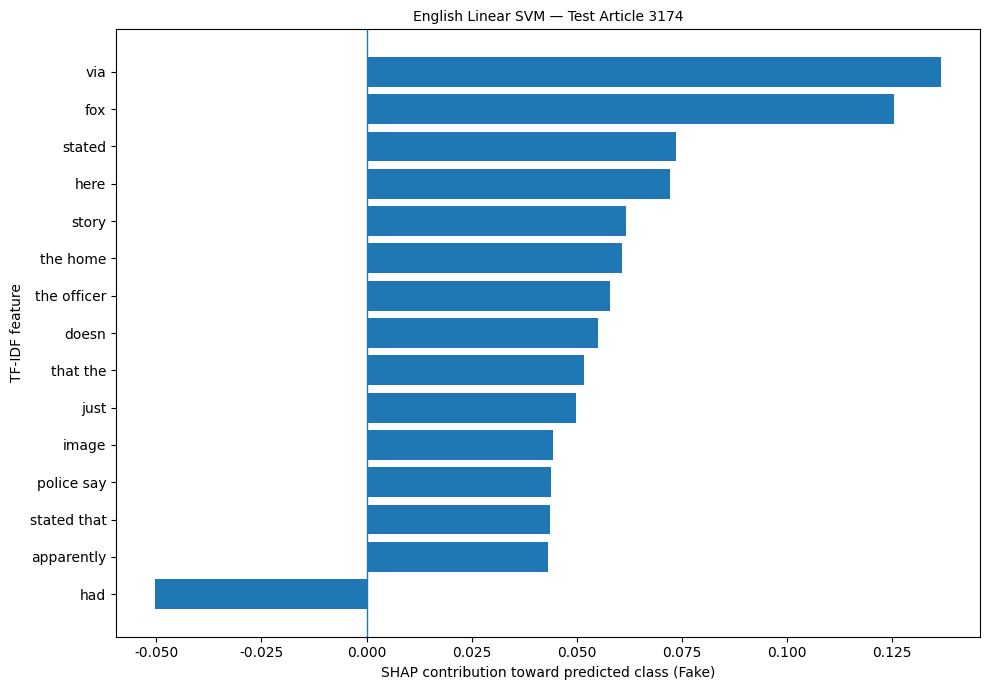

/tmp/ipykernel_16564/903597899.py:74: UserWarning: Glyph 108 (l) missing from font(s) Noto Serif Devanagari.
  plt.tight_layout()
/tmp/ipykernel_16564/903597899.py:74: UserWarning: Glyph 112 (p) missing from font(s) Noto Serif Devanagari.
  plt.tight_layout()
/tmp/ipykernel_16564/903597899.py:76: UserWarning: Glyph 108 (l) missing from font(s) Noto Serif Devanagari.
  plt.savefig(
/tmp/ipykernel_16564/903597899.py:76: UserWarning: Glyph 112 (p) missing from font(s) Noto Serif Devanagari.
  plt.savefig(
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 108 (l) missing from font(s) Noto Serif Devanagari.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 112 (p) missing from font(s) Noto Serif Devanagari.
  fig.canvas.print_figure(bytes_io, **kw)


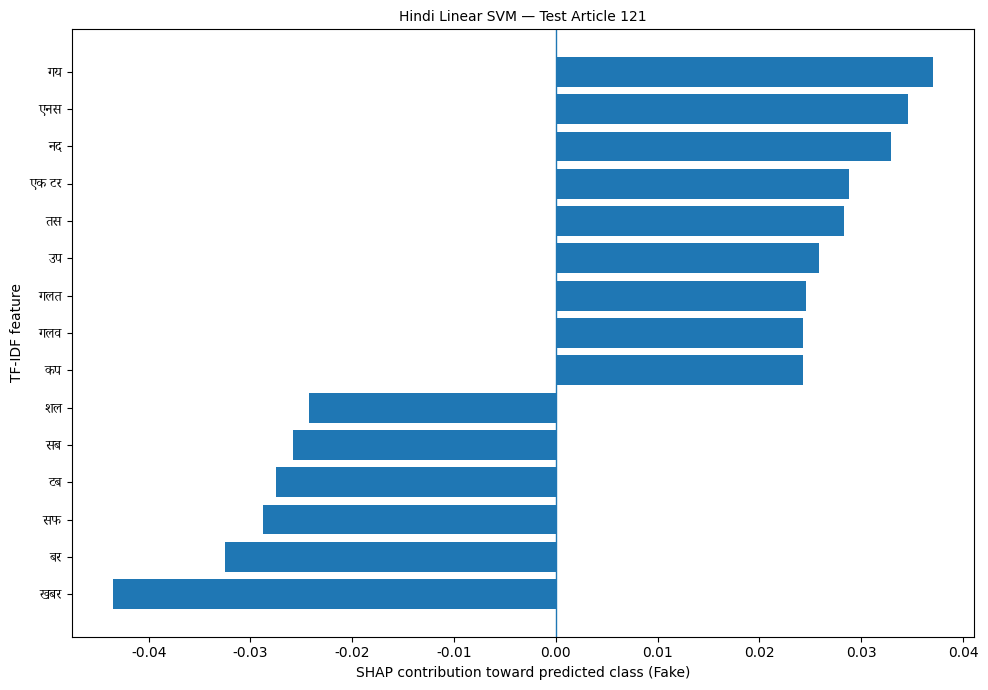

In [ ]:
# English chart
plot_shap_features(
    shap_features_en,
    3174,
    "English",
    f"{XAI_OUTPUT_DIR}/shap_svm_english_3174.png"
)

# Hindi chart
plot_shap_features(
    shap_features_hi,
    121,
    "Hindi",
    f"{XAI_OUTPUT_DIR}/shap_svm_hindi_121.png"
)

In [ ]:
# ============================================================
# Save SHAP Feature Tables
# ============================================================

shap_features_en.to_csv(
    f"{XAI_OUTPUT_DIR}/shap_svm_english_features.csv",
    index=False,
    encoding="utf-8-sig"
)

shap_features_hi.to_csv(
    f"{XAI_OUTPUT_DIR}/shap_svm_hindi_features.csv",
    index=False,
    encoding="utf-8-sig"
)

print("English SHAP rows:", len(shap_features_en))
print("Hindi SHAP rows:", len(shap_features_hi))

print("SHAP tables and charts saved successfully.")

English SHAP rows: 90
Hindi SHAP rows: 90
SHAP tables and charts saved successfully.


### **10.3. LIME — Explain All Selected SVM Articles**

In [ ]:
def explain_all_svm_examples(
    examples,
    explainer,
    predict_fn,
    language,
    output_dir
):
    all_results = []

    for _, article in examples.iterrows():

        test_index = int(article["test_index"])
        predicted_label = int(article["svm_prediction"])

        print(f"{language}: explaining article {test_index}")

        explanation = explainer.explain_instance(
            article["text"],
            predict_fn,
            labels=[predicted_label],
            num_features=15,
            num_samples=1000
        )

        explanation.save_to_file(
            os.path.join(
                output_dir,
                f"lime_svm_{language.lower()}_{test_index}.html"
            )
        )

        for rank, (feature, weight) in enumerate(
            explanation.as_list(label=predicted_label),
            start=1
        ):

            all_results.append({
                "Language": language,
                "test_index": test_index,
                "true_label": int(article["true_label"]),
                "svm_prediction": predicted_label,
                "feature_rank": rank,
                "feature": str(feature),
                "lime_weight": float(weight)
            })

    return pd.DataFrame(all_results)


lime_all_en = explain_all_svm_examples(
    xai_examples_en,
    lime_en,
    predict_svm_en,
    "English",
    XAI_OUTPUT_DIR
)

lime_all_hi = explain_all_svm_examples(
    xai_examples_hi,
    lime_hi,
    predict_svm_hi,
    "Hindi",
    XAI_OUTPUT_DIR
)

lime_all_en.to_csv(
    f"{XAI_OUTPUT_DIR}/lime_svm_english_all.csv",
    index=False,
    encoding="utf-8-sig"
)

lime_all_hi.to_csv(
    f"{XAI_OUTPUT_DIR}/lime_svm_hindi_all.csv",
    index=False,
    encoding="utf-8-sig"
)

print("English LIME rows:", len(lime_all_en))
print("Hindi LIME rows:", len(lime_all_hi))
print("All selected SVM explanations saved.")

English: explaining article 1428
English: explaining article 3025
English: explaining article 3174
English: explaining article 4602
English: explaining article 5834
English: explaining article 6703
Hindi: explaining article 25
Hindi: explaining article 121
Hindi: explaining article 201
Hindi: explaining article 366
Hindi: explaining article 542
Hindi: explaining article 1323
English LIME rows: 90
Hindi LIME rows: 90
All selected SVM explanations saved.


### **10.4. XAI — XLM-R LIME Setup - English Article**

In [ ]:
from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification
)
from lime.lime_text import LimeTextExplainer

BASE_DIR = "/content/drive/MyDrive/Colab Notebooks/Dissertation"

XAI_OUTPUT_DIR = os.path.join(BASE_DIR, "xai_outputs")
os.makedirs(XAI_OUTPUT_DIR, exist_ok=True)

ENGLISH_MODEL_PATH = os.path.join(
    BASE_DIR, "xlmr_english_best"
)

HINDI_MODEL_PATH = os.path.join(
    BASE_DIR, "xlmr_hindi_best"
)

CLASS_NAMES = ["Fake", "Real"]
DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

MAX_LENGTH = 512

print("Device:", DEVICE)
print("English checkpoint:", os.path.isdir(ENGLISH_MODEL_PATH))
print("Hindi checkpoint:", os.path.isdir(HINDI_MODEL_PATH))

Device: cuda
English checkpoint: True
Hindi checkpoint: True


In [ ]:
# XAI — XLM-R Prediction Function for LIME

def load_xlmr_for_xai(model_path):

    tokenizer_xai = AutoTokenizer.from_pretrained(
        model_path
    )

    model_xai = AutoModelForSequenceClassification.from_pretrained(
        model_path
    )

    model_xai.to(DEVICE)
    model_xai.eval()

    return tokenizer_xai, model_xai


def make_xlmr_lime_predictor(
    tokenizer_xai,
    model_xai,
    batch_size=4
):

    def predict_fn(texts):

        texts = [str(text) for text in texts]
        probabilities = []

        for start in range(0, len(texts), batch_size):

            batch_texts = texts[start:start + batch_size]

            inputs = tokenizer_xai(
                batch_texts,
                padding=True,
                truncation=True,
                max_length=MAX_LENGTH,
                return_tensors="pt"
            )

            inputs = {
                key: value.to(DEVICE)
                for key, value in inputs.items()
                if key in ["input_ids", "attention_mask"]
            }

            with torch.inference_mode():

                outputs = model_xai(**inputs)

                batch_probs = torch.softmax(
                    outputs.logits,
                    dim=-1
                )

            probabilities.append(
                batch_probs.cpu().numpy()
            )

        return np.concatenate(probabilities, axis=0)

    return predict_fn

In [ ]:
# XLM-R LIME — First English Explanation

tokenizer_xai_en, model_xai_en = load_xlmr_for_xai(
    ENGLISH_MODEL_PATH
)

predict_xlmr_en = make_xlmr_lime_predictor(
    tokenizer_xai_en,
    model_xai_en,
    batch_size=4
)

lime_xlmr_en = LimeTextExplainer(
    class_names=CLASS_NAMES,
    split_expression=r"\s+",
    bow=True,
    random_state=42
)

english_example = xai_examples_en[
    xai_examples_en["test_index"] == 3174
].iloc[0]

# Confirm the restored model agrees with saved predictions.
original_scores = predict_xlmr_en([
    english_example["text"]
])

restored_prediction = int(original_scores.argmax(axis=1)[0])
saved_prediction = int(english_example["predicted_label"])

print("Saved XLM-R prediction:", CLASS_NAMES[saved_prediction])
print("Restored prediction:", CLASS_NAMES[restored_prediction])

assert restored_prediction == saved_prediction, (
    "Saved and restored XLM-R predictions do not match."
)

exp_xlmr_en = lime_xlmr_en.explain_instance(
    english_example["text"],
    predict_xlmr_en,
    labels=[restored_prediction],
    num_features=15,
    num_samples=300
)

display(
    exp_xlmr_en.as_list(
        label=restored_prediction
    )
)

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

Saved XLM-R prediction: Fake
Restored prediction: Fake


[(np.str_('which'), 1.9278279899459628e-06),
 (np.str_('more'), 1.4012352314986718e-06),
 (np.str_('kids'), 1.1753296129738902e-06),
 (np.str_('ten'), 1.1663674813533706e-06),
 (np.str_('visit'), 1.0319792984085834e-06),
 (np.str_('or'), 9.76980412731708e-07),
 (np.str_('there.'), 8.153466710102853e-07),
 (np.str_('an'), 7.454631205921729e-07),
 (np.str_('up.'), 7.202270287001383e-07),
 (np.str_('one'), 7.076208989140541e-07),
 (np.str_('Police'), 6.046025876633113e-07),
 (np.str_('Here'), 5.275154645410848e-07),
 (np.str_('this'), 3.5600702202590403e-07),
 (np.str_('happened,'), 3.4769741520994386e-07),
 (np.str_('at'), 2.805748668147836e-07)]

In [ ]:
# Save First XLM-R LIME Explanation

exp_xlmr_en.save_to_file(
    f"{XAI_OUTPUT_DIR}/lime_xlmr_english_3174.html"
)

lime_xlmr_en_df = pd.DataFrame(
    exp_xlmr_en.as_list(
        label=restored_prediction
    ),
    columns=["Feature", "LIME_Weight"]
)

lime_xlmr_en_df.to_csv(
    f"{XAI_OUTPUT_DIR}/lime_xlmr_english_3174.csv",
    index=False,
    encoding="utf-8-sig"
)

print("English XLM-R LIME explanation saved.")

English XLM-R LIME explanation saved.


In [ ]:
# XLM-R LIME — Diagnostic Check

text_en = str(english_example["text"])
words = text_en.split()

test_variants = [
    text_en,
    " ".join(words[:int(len(words) * 0.75)]),
    " ".join(words[:int(len(words) * 0.50)]),
    " ".join(words[:int(len(words) * 0.25)]),
    " ".join(words[:50]),
    ""
]

scores = predict_xlmr_en(test_variants)

diagnostic_df = pd.DataFrame({
    "Variant": [
        "Original",
        "First 75% of words",
        "First 50% of words",
        "First 25% of words",
        "First 50 words",
        "Empty text"
    ],
    "Fake_score": scores[:, 0],
    "Real_score": scores[:, 1],
    "Predicted_class": [
        CLASS_NAMES[i] for i in scores.argmax(axis=1)
    ]
})

display(
    diagnostic_df.style.format({
        "Fake_score": "{:.12f}",
        "Real_score": "{:.12f}"
    })
)

,Variant,Fake_score,Real_score,Predicted_class
0,Original,0.999998569489,0.000001472315,Fake
1,First 75% of words,0.999998569489,0.000001487425,Fake
2,First 50% of words,0.999998450279,0.000001504114,Fake
3,First 25% of words,0.999997258186,0.000002696695,Fake
4,First 50 words,0.999998211861,0.000001817626,Fake
5,Empty text,0.561356782913,0.438643246889,Fake


In [ ]:
# Check XLM-R Input Coverage

full_tokens = tokenizer_xai_en(
    text_en,
    truncation=False,
    add_special_tokens=True
)["input_ids"]

used_tokens = tokenizer_xai_en(
    text_en,
    truncation=True,
    max_length=512,
    add_special_tokens=True
)["input_ids"]

print("Full subword-token count:", len(full_tokens))
print("Tokens supplied to XLM-R:", len(used_tokens))
print("Truncation occurred:", len(full_tokens) > 512)

Full subword-token count: 500
Tokens supplied to XLM-R: 500
Truncation occurred: False


In [ ]:
# XLM-R — Raw Logit and Probability Diagnostic

def predict_xlmr_diagnostics(texts, tokenizer_xai, model_xai,
                             batch_size=4):
    rows = []

    for start in range(0, len(texts), batch_size):
        batch_texts = [
            str(t) for t in texts[start:start + batch_size]
        ]

        inputs = tokenizer_xai(
            batch_texts,
            padding=True,
            truncation=True,
            max_length=512,
            return_tensors="pt"
        )

        inputs = {
            k: v.to(DEVICE)
            for k, v in inputs.items()
            if k in ["input_ids", "attention_mask"]
        }

        with torch.inference_mode():
            logits = model_xai(**inputs).logits
            probs = torch.softmax(logits, dim=-1)

        logits = logits.cpu().numpy()
        probs = probs.cpu().numpy()

        for logit, prob in zip(logits, probs):
            rows.append({
                "logit_margin_real_minus_fake":
                    float(logit[1] - logit[0]),
                "fake_score": float(prob[0]),
                "real_score": float(prob[1]),
                "prediction": int(np.argmax(prob))
            })

    return pd.DataFrame(rows)

In [ ]:
english_diagnostics = predict_xlmr_diagnostics(
    xai_examples_en["text"].tolist(),
    tokenizer_xai_en,
    model_xai_en
)

english_diagnostics.insert(
    0,
    "test_index",
    xai_examples_en["test_index"].to_numpy()
)

english_diagnostics.insert(
    1,
    "true_label",
    xai_examples_en["true_label"].to_numpy()
)

display(english_diagnostics.round(6))

,test_index,true_label,logit_margin_real_minus_fake,fake_score,real_score,prediction
0,1428,1,13.434090,0.000001,0.999999,1
1,3025,0,12.629648,0.000003,0.999997,1
2,3174,0,-13.428673,0.999999,0.000001,0
3,4602,0,-13.405563,0.999998,0.000002,0
4,5834,1,13.423670,0.000001,0.999999,1
5,6703,1,-2.401878,0.916970,0.083030,0


In [ ]:
def get_model_visible_text(text, tokenizer_xai):
    encoded = tokenizer_xai(
        str(text),
        truncation=True,
        max_length=512,
        add_special_tokens=True
    )

    return tokenizer_xai.decode(
        encoded["input_ids"],
        skip_special_tokens=True,
        clean_up_tokenization_spaces=False
    )


visible_text_en = get_model_visible_text(
    english_example["text"],
    tokenizer_xai_en
)

original_prediction = predict_xlmr_en(
    [english_example["text"]]
).argmax(axis=1)[0]

visible_prediction = predict_xlmr_en(
    [visible_text_en]
).argmax(axis=1)[0]

print("Original prediction:", CLASS_NAMES[int(original_prediction)])
print("Visible-text prediction:", CLASS_NAMES[int(visible_prediction)])
print("Visible-text characters:", len(visible_text_en))

Original prediction: Fake
Visible-text prediction: Fake
Visible-text characters: 2064


In [ ]:
english_diagnostics = predict_xlmr_diagnostics(
    xai_examples_en["text"].tolist(),
    tokenizer_xai_en,
    model_xai_en
)

english_diagnostics.insert(
    0,
    "test_index",
    xai_examples_en["test_index"].to_numpy()
)

english_diagnostics.insert(
    1,
    "true_label",
    xai_examples_en["true_label"].to_numpy()
)

display(english_diagnostics.round(6))

,test_index,true_label,logit_margin_real_minus_fake,fake_score,real_score,prediction
0,1428,1,13.434090,0.000001,0.999999,1
1,3025,0,12.629648,0.000003,0.999997,1
2,3174,0,-13.428673,0.999999,0.000001,0
3,4602,0,-13.405563,0.999998,0.000002,0
4,5834,1,13.423670,0.000001,0.999999,1
5,6703,1,-2.401878,0.916970,0.083030,0


In [ ]:
# XLM-R — Raw Logit Margin Predictor

def predict_xlmr_margin(texts, tokenizer_xai, model_xai,
                        batch_size=4):

    margins = []

    for start in range(0, len(texts), batch_size):

        batch_texts = [
            str(t) for t in texts[start:start + batch_size]
        ]

        inputs = tokenizer_xai(
            batch_texts,
            padding=True,
            truncation=True,
            max_length=512,
            return_tensors="pt"
        )

        inputs = {
            k: v.to(DEVICE)
            for k, v in inputs.items()
            if k in ["input_ids", "attention_mask"]
        }

        with torch.inference_mode():
            logits = model_xai(**inputs).logits

        margin = (
            logits[:, 1] - logits[:, 0]
        ).cpu().numpy()

        margins.extend(margin.tolist())

    return np.asarray(margins)

In [ ]:
# XLM-R — Article 3025 Diagnostic

article_3025 = xai_examples_en[
    xai_examples_en["test_index"] == 3025
].iloc[0]

visible_text_3025 = get_model_visible_text(
    article_3025["text"],
    tokenizer_xai_en
)

original_margin = predict_xlmr_margin(
    [article_3025["text"]],
    tokenizer_xai_en,
    model_xai_en
)[0]

visible_margin = predict_xlmr_margin(
    [visible_text_3025],
    tokenizer_xai_en,
    model_xai_en
)[0]

print("Original margin:", original_margin)
print("Visible-text margin:", visible_margin)
print("Absolute difference:", abs(original_margin - visible_margin))
print("Visible-text characters:", len(visible_text_3025))

Original margin: 12.629648208618164
Visible-text margin: 12.629648208618164
Absolute difference: 0.0
Visible-text characters: 429


In [ ]:
words = visible_text_3025.split()

variants = [
    visible_text_3025,
    " ".join(words[:int(len(words) * 0.75)]),
    " ".join(words[:int(len(words) * 0.50)]),
    " ".join(words[:int(len(words) * 0.25)]),
    ""
]

margins = predict_xlmr_margin(
    variants,
    tokenizer_xai_en,
    model_xai_en
)

display(pd.DataFrame({
    "Variant": [
        "Visible text",
        "First 75%",
        "First 50%",
        "First 25%",
        "Empty text"
    ],
    "Real_minus_Fake_margin": margins
}))

,Variant,Real_minus_Fake_margin
0,Visible text,12.629651
1,First 75%,-7.790463
2,First 50%,8.962465
3,First 25%,-9.230242
4,Empty text,-0.246670


In [ ]:
# XLM-R LIME — English Article 3025

article_3025 = xai_examples_en[
    xai_examples_en["test_index"] == 3025
].iloc[0]

visible_text_3025 = get_model_visible_text(
    article_3025["text"],
    tokenizer_xai_en
)

# Confirm prediction agreement
original_scores = predict_xlmr_en(
    [article_3025["text"]]
)

visible_scores = predict_xlmr_en(
    [visible_text_3025]
)

assert np.argmax(original_scores) == np.argmax(visible_scores)

predicted_label = int(np.argmax(visible_scores))

print("Original scores:", original_scores[0])
print("Visible-text scores:", visible_scores[0])
print("Predicted class:", CLASS_NAMES[predicted_label])

exp_xlmr_3025 = lime_xlmr_en.explain_instance(
    visible_text_3025,
    predict_xlmr_en,
    labels=[predicted_label],
    num_features=15,
    num_samples=1000
)

lime_3025_df = pd.DataFrame(
    exp_xlmr_3025.as_list(label=predicted_label),
    columns=["Feature", "LIME_Weight"]
)

display(lime_3025_df)

print("LIME local fidelity (R²):", exp_xlmr_3025.score)

Original scores: [3.2734981e-06 9.9999678e-01]
Visible-text scores: [3.2734981e-06 9.9999678e-01]
Predicted class: Real


,Feature,LIME_Weight
0,said.,0.520848
1,Tuesday.,0.221908
2,"public,",0.195076
3,on,0.162672
4,"Woods,",0.160299
5,U.S.,0.134844
6,I,-0.083678
7,"attack,",0.076104
8,him,-0.071670
9,appeared,0.071144


LIME local fidelity (R²): 0.6982530344313035


In [ ]:
exp_xlmr_3025.save_to_file(
    f"{XAI_OUTPUT_DIR}/lime_xlmr_english_3025.html"
)

lime_3025_df.to_csv(
    f"{XAI_OUTPUT_DIR}/lime_xlmr_english_3025.csv",
    index=False,
    encoding="utf-8-sig"
)

print("English article 3025 explanation saved.")

English article 3025 explanation saved.


### **10.5. XAI — XLM-R SHAP Setup - English Article**

In [ ]:
# XLM-R SHAP — Raw Logit Margin

import shap
import numpy as np

def make_xlmr_shap_predictor(
    tokenizer_xai,
    model_xai,
    batch_size=4
):

    def predict_fn(texts):

        texts = [str(t) for t in texts]

        margins = predict_xlmr_margin(
            texts,
            tokenizer_xai,
            model_xai,
            batch_size=batch_size
        )

        return np.asarray(margins, dtype=float)

    return predict_fn


shap_predict_xlmr_en = make_xlmr_shap_predictor(
    tokenizer_xai_en,
    model_xai_en
)

In [ ]:
# XLM-R SHAP — Text Explainer

masker_xlmr_en = shap.maskers.Text(
    tokenizer_xai_en
)

explainer_xlmr_en = shap.Explainer(
    shap_predict_xlmr_en,
    masker_xlmr_en,
    algorithm="partition"
)

print("English XLM-R SHAP explainer ready.")

English XLM-R SHAP explainer ready.


In [ ]:
# XLM-R SHAP — Article 3025

shap_xlmr_3025 = explainer_xlmr_en(
    [visible_text_3025],
    max_evals=1024,
    batch_size=4
)

print(
    "SHAP output shape:",
    shap_xlmr_3025.values.shape
)

print(
    "Base value:",
    shap_xlmr_3025.base_values
)

print(
    "Sum of SHAP values:",
    shap_xlmr_3025.values.sum()
)

SHAP output shape: (1, 109)
Base value: [-13.02549171]
Sum of SHAP values: 25.65513992309571


In [ ]:
# XLM-R SHAP — Additivity Check

base_value = float(
    np.asarray(shap_xlmr_3025.base_values).ravel()[0]
)

shap_sum = float(
    np.asarray(shap_xlmr_3025.values).sum()
)

reconstructed_margin = base_value + shap_sum

direct_margin = float(
    shap_predict_xlmr_en([visible_text_3025])[0]
)

difference = abs(reconstructed_margin - direct_margin)

print("SHAP base value:", base_value)
print("Sum of SHAP values:", shap_sum)
print("Reconstructed margin:", reconstructed_margin)
print("Direct model margin:", direct_margin)
print("Absolute difference:", difference)

SHAP base value: -13.025491714477539
Sum of SHAP values: 25.65513992309571
Reconstructed margin: 12.629648208618171
Direct model margin: 12.629648208618164
Absolute difference: 7.105427357601002e-15


In [ ]:
# Inspect SHAP Token Attribution

tokens = np.asarray(
    shap_xlmr_3025.data[0]
).ravel()

values = np.asarray(
    shap_xlmr_3025.values[0]
).ravel()

assert len(tokens) == len(values)

token_table = pd.DataFrame({
    "Token": [str(token) for token in tokens],
    "SHAP_Value": values
})

token_table["Absolute_SHAP"] = (
    token_table["SHAP_Value"].abs()
)

display(
    token_table.sort_values(
        "Absolute_SHAP",
        ascending=False
    ).head(20)
)

,Token,SHAP_Value,Absolute_SHAP
33,Tuesday,5.936782,5.936782
106,said,1.963085,1.963085
34,.,-1.483700,1.483700
7,U,1.433625,1.433625
9,S,1.245974,1.245974
59,Khan,1.101975,1.101975
31,on,1.048582,1.048582
2,Wood,0.843913,0.843913
3,s,0.656985,0.656985
8,.,0.631004,0.631004


In [ ]:
token_table.to_csv(
    f"{XAI_OUTPUT_DIR}/shap_xlmr_english_3025_tokens.csv",
    index=False,
    encoding="utf-8-sig"
)

print("English transformer SHAP token table saved.")

English transformer SHAP token table saved.


In [ ]:
# XLM-R SHAP — Input Reconstruction Diagnostic

shap_tokens = [
    str(token)
    for token in shap_xlmr_3025.data[0]
]

shap_reconstructed_text = "".join(shap_tokens)

texts_to_check = {
    "Original article": str(article_3025["text"]),
    "Model-visible text": visible_text_3025,
    "SHAP token reconstruction": shap_reconstructed_text
}

rows = []

for name, text_value in texts_to_check.items():

    margin = float(
        shap_predict_xlmr_en([text_value])[0]
    )

    token_count = len(
        tokenizer_xai_en(
            text_value,
            truncation=False,
            add_special_tokens=True
        )["input_ids"]
    )

    rows.append({
        "Input": name,
        "Characters": len(text_value),
        "Token_count": token_count,
        "Margin": margin
    })

display(pd.DataFrame(rows))

print(
    "Visible text equals SHAP reconstruction:",
    visible_text_3025 == shap_reconstructed_text
)

print(
    "First 150 reconstructed characters:",
    repr(shap_reconstructed_text[:150])
)

,Input,Characters,Token_count,Margin
0,Original article,429,109,12.629648
1,Model-visible text,429,109,12.629648
2,SHAP token reconstruction,429,109,12.629648


Visible text equals SHAP reconstruction: True
First 150 reconstructed characters: 'Charles Woods, father of U.S. Navy SEAL Tyrone Woods, who was killed during the Benghazi attack, appeared on CNN Tuesday. CNN Newsroom host Carol Cost'


In [ ]:
# XLM-R SHAP — Compare Tokenisation

ids_visible = tokenizer_xai_en(
    visible_text_3025,
    truncation=True,
    max_length=512
)["input_ids"]

ids_shap = tokenizer_xai_en(
    shap_reconstructed_text,
    truncation=True,
    max_length=512
)["input_ids"]

print("Visible token count:", len(ids_visible))
print("SHAP token count:", len(ids_shap))

print("Token IDs identical:", ids_visible == ids_shap)

differences = [
    i for i, (a, b) in enumerate(
        zip(ids_visible, ids_shap)
    )
    if a != b
]

print("Number of differing token positions:", len(differences))
print("First differing positions:", differences[:20])

print("\nFirst 10 visible token IDs:", ids_visible[:10])
print("First 10 SHAP token IDs:", ids_shap[:10])

Visible token count: 109
SHAP token count: 109
Token IDs identical: True
Number of differing token positions: 0
First differing positions: []

First 10 visible token IDs: [0, 28166, 39076, 7, 4, 67373, 111, 345, 5, 294]
First 10 SHAP token IDs: [0, 28166, 39076, 7, 4, 67373, 111, 345, 5, 294]


In [ ]:
# XLM-R SHAP — Consistent Explanation Input

shap_input_3025 = shap_reconstructed_text

# Check direct model output
target_margin = float(
    shap_predict_xlmr_en([shap_input_3025])[0]
)

print("Target margin:", target_margin)

# Check tokenisation
target_ids = tokenizer_xai_en(
    shap_input_3025,
    truncation=True,
    max_length=512
)["input_ids"]

print("Token count:", len(target_ids))

# Reconstruct SHAP token segments again
reconstructed_again = "".join(
    tokenizer_xai_en.convert_ids_to_tokens(target_ids)
)

print(
    "Target prediction:",
    CLASS_NAMES[int(target_margin > 0)]
)

Target margin: 12.629648208618164
Token count: 109
Target prediction: Real


In [ ]:
import shap
import transformers

print("SHAP version:", shap.__version__)
print("Transformers version:", transformers.__version__)
print("Tokenizer class:", type(tokenizer_xai_en).__name__)
print("Tokenizer fast:", tokenizer_xai_en.is_fast)

SHAP version: 0.52.0
Transformers version: 5.18.0
Tokenizer class: XLMRobertaTokenizer
Tokenizer fast: True


In [ ]:
# SHAP Text Masker Compatibility Check

masker_test = shap.maskers.Text(tokenizer_xai_en)

print("Masker class:", type(masker_test).__name__)
print("Mask token:", masker_test.mask_token)
print("Mask token ID:", masker_test.mask_token_id)

print(
    "Tokenizer output type:",
    type(masker_test.tokenizer(visible_text_3025)).__name__
)

print(
    "Token segments:",
    len(masker_test.token_segments(visible_text_3025))
)

Masker class: Text
Mask token: <mask>
Mask token ID: 250001
Tokenizer output type: BatchEncoding
Token segments: 2


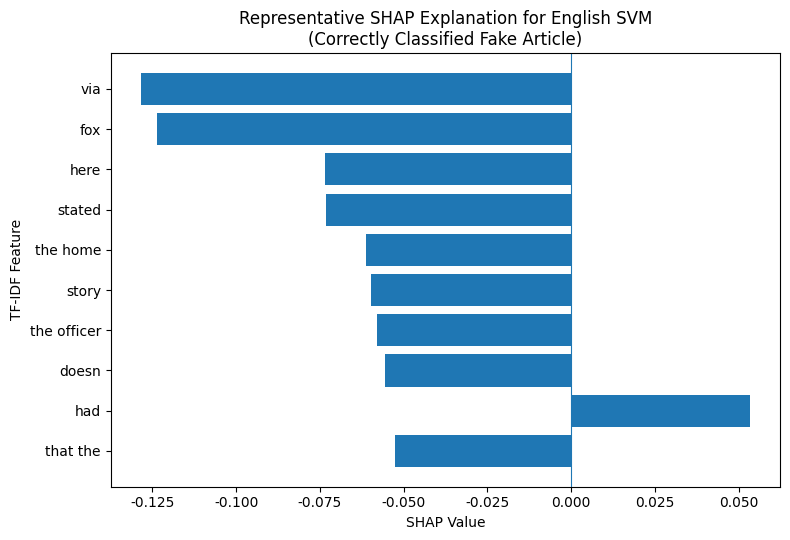

In [ ]:
# Representative English SVM example

example_index = 3174

# Get text from English test set
example_text = X_test_en.iloc[example_index]

# Transform using fitted English TF-IDF vectorizer
example_tfidf = tfidf_en.transform([example_text])

# SHAP explainer for linear SVM
explainer = shap.LinearExplainer(
    svm_en,
    X_train_en_tfidf
)

# Calculate SHAP values
shap_values = explainer(example_tfidf)

# Feature names
feature_names = np.array(
    tfidf_en.get_feature_names_out()
)

# Get SHAP values for this observation
values = shap_values.values[0]

# Find 10 features with largest absolute SHAP contribution
top_indices = np.argsort(np.abs(values))[-10:]

top_features = feature_names[top_indices]
top_values = values[top_indices]

# Plot
fig, ax = plt.subplots(figsize=(8, 5.5))

ax.barh(
    top_features,
    top_values
)

ax.axvline(0, linewidth=0.8)

ax.set_xlabel("SHAP Value")
ax.set_ylabel("TF-IDF Feature")
ax.set_title(
    "Representative SHAP Explanation for English SVM\n"
    "(Correctly Classified Fake Article)"
)

plt.tight_layout()

plt.savefig(
    "Figure_4_4_English_SVM_SHAP.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [ ]:
# SHAP — Check Reconstruction Stability

def check_shap_reconstruction(text, tokenizer, masker):

    segments, offsets = masker.token_segments(text)

    reconstructed = "".join(str(s) for s in segments)

    original_ids = tokenizer(
        text,
        truncation=True,
        max_length=512
    )["input_ids"]

    reconstructed_ids = tokenizer(
        reconstructed,
        truncation=True,
        max_length=512
    )["input_ids"]

    differences = [
        i for i, (a, b) in enumerate(
            zip(original_ids, reconstructed_ids)
        )
        if a != b
    ]

    return {
        "Original token count": len(original_ids),
        "Reconstructed token count": len(reconstructed_ids),
        "Token IDs identical": original_ids == reconstructed_ids,
        "Differing positions": differences[:20],
        "Number of differences": len(differences)
    }


print("Original visible text:")
print(
    check_shap_reconstruction(
        visible_text_3025,
        tokenizer_xai_en,
        masker_xlmr_en
    )
)

print("\nSHAP-reconstructed text:")
print(
    check_shap_reconstruction(
        shap_reconstructed_text,
        tokenizer_xai_en,
        masker_xlmr_en
    )
)

Original visible text:
{'Original token count': 109, 'Reconstructed token count': 109, 'Token IDs identical': True, 'Differing positions': [], 'Number of differences': 0}

SHAP-reconstructed text:
{'Original token count': 109, 'Reconstructed token count': 109, 'Token IDs identical': True, 'Differing positions': [], 'Number of differences': 0}


In [ ]:
# XLM-R SHAP — Stable English Input

stable_text_en = shap_reconstructed_text

shap_xlmr_en_final = explainer_xlmr_en(
    [stable_text_en],
    max_evals=1024,
    batch_size=4
)

print(
    "SHAP shape:",
    shap_xlmr_en_final.values.shape
)

SHAP shape: (1, 109)


In [ ]:
# XLM-R SHAP — Final Additivity Check

base = float(
    np.asarray(shap_xlmr_en_final.base_values).ravel()[0]
)

contributions = float(
    np.asarray(shap_xlmr_en_final.values).sum()
)

reconstructed = base + contributions

direct = float(
    shap_predict_xlmr_en([stable_text_en])[0]
)

difference = abs(reconstructed - direct)

print("SHAP base value:", base)
print("SHAP contribution sum:", contributions)
print("Reconstructed margin:", reconstructed)
print("Direct model margin:", direct)
print("Absolute difference:", difference)

print(
    "Additivity check:",
    "PASS" if np.isclose(
        reconstructed,
        direct,
        atol=1e-3,
        rtol=1e-4
    ) else "REVIEW"
)

SHAP base value: -13.025491714477539
SHAP contribution sum: 25.65513992309571
Reconstructed margin: 12.629648208618171
Direct model margin: 12.629648208618164
Absolute difference: 7.105427357601002e-15
Additivity check: PASS


### **10.6. XAI - XLM-R LIME Setup - Hindi Article**

In [ ]:
# Hindi XLM-R XAI — Load Saved Model

from lime.lime_text import LimeTextExplainer

# Release English model GPU memory if it is still loaded
for name in ["model_xai_en", "predict_xlmr_en"]:
    if name in globals():
        del globals()[name]

gc.collect()

if torch.cuda.is_available():
    torch.cuda.empty_cache()

tokenizer_xai_hi, model_xai_hi = load_xlmr_for_xai(
    HINDI_MODEL_PATH
)

predict_xlmr_hi = make_xlmr_lime_predictor(
    tokenizer_xai_hi,
    model_xai_hi,
    batch_size=4
)

lime_xlmr_hi = LimeTextExplainer(
    class_names=CLASS_NAMES,
    split_expression=r"\s+",
    bow=True,
    random_state=42
)

print("Hindi model loaded successfully.")
print("Device:", next(model_xai_hi.parameters()).device)
print("Selected Hindi articles:", len(xai_examples_hi))

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

Hindi model loaded successfully.
Device: cuda:0
Selected Hindi articles: 6


In [ ]:
# Hindi XLM-R — Check Restored Predictions


hi_scores = predict_xlmr_hi(
    xai_examples_hi["text"].astype(str).tolist()
)

hi_predictions = hi_scores.argmax(axis=1)

hindi_prediction_check = xai_examples_hi[
    ["test_index", "true_label", "predicted_label"]
].copy()

hindi_prediction_check["restored_prediction"] = hi_predictions

hindi_prediction_check["prediction_matches"] = (
    hindi_prediction_check["predicted_label"].astype(int)
    == hindi_prediction_check["restored_prediction"]
)

hindi_prediction_check["Fake_score"] = hi_scores[:, 0]
hindi_prediction_check["Real_score"] = hi_scores[:, 1]

display(hindi_prediction_check)

print(
    "All predictions match:",
    hindi_prediction_check["prediction_matches"].all()
)

,test_index,true_label,predicted_label,restored_prediction,prediction_matches,Fake_score,Real_score
25,25,1,0,0,True,0.999925,0.000075
121,121,0,0,0,True,0.999981,0.000019
201,201,0,1,1,True,0.000056,0.999944
366,366,0,0,0,True,0.999978,0.000022
542,542,1,1,1,True,0.000012,0.999988
1323,1323,1,1,1,True,0.000014,0.999986


All predictions match: True


In [ ]:
# Hindi XLM-R — Diagnostic Table

hindi_diagnostics = predict_xlmr_diagnostics(
    xai_examples_hi["text"].astype(str).tolist(),
    tokenizer_xai_hi,
    model_xai_hi
)

hindi_diagnostics.insert(
    0,
    "test_index",
    xai_examples_hi["test_index"].to_numpy()
)

hindi_diagnostics.insert(
    1,
    "true_label",
    xai_examples_hi["true_label"].to_numpy()
)

hindi_diagnostics["full_token_count"] = [
    len(
        tokenizer_xai_hi(
            str(text),
            truncation=False,
            add_special_tokens=True,
            verbose=False
        )["input_ids"]
    )
    for text in xai_examples_hi["text"]
]

hindi_diagnostics["truncated"] = (
    hindi_diagnostics["full_token_count"] > 512
)

display(hindi_diagnostics.round(6))

,test_index,true_label,logit_margin_real_minus_fake,fake_score,real_score,prediction,full_token_count,truncated
0,25,1,-9.492447,0.999925,0.000075,0,668,True
1,121,0,-10.867266,0.999981,0.000019,0,1986,True
2,201,0,9.790945,0.000056,0.999944,1,1903,True
3,366,0,-10.738419,0.999978,0.000022,0,838,True
4,542,1,11.303588,0.000012,0.999988,1,687,True
5,1323,1,11.187703,0.000014,0.999986,1,710,True


In [ ]:
# Hindi XLM-R — Article 25 Input Validation

article_hi_25 = xai_examples_hi[
    xai_examples_hi["test_index"] == 25
].iloc[0]

original_text_hi = str(article_hi_25["text"])

visible_text_hi = get_model_visible_text(
    original_text_hi,
    tokenizer_xai_hi
)

original_margin_hi = float(
    predict_xlmr_margin(
        [original_text_hi],
        tokenizer_xai_hi,
        model_xai_hi
    )[0]
)

visible_margin_hi = float(
    predict_xlmr_margin(
        [visible_text_hi],
        tokenizer_xai_hi,
        model_xai_hi
    )[0]
)

print("Article index:", article_hi_25["test_index"])
print("True label:", CLASS_NAMES[int(article_hi_25["true_label"])])
print("Original margin:", original_margin_hi)
print("Visible-text margin:", visible_margin_hi)
print("Absolute difference:", abs(original_margin_hi - visible_margin_hi))
print("Original characters:", len(original_text_hi))
print("Visible characters:", len(visible_text_hi))
print("Original prediction:", CLASS_NAMES[int(original_margin_hi > 0)])
print("Visible prediction:", CLASS_NAMES[int(visible_margin_hi > 0)])

Article index: 25
True label: Real
Original margin: -9.492447853088379
Visible-text margin: -9.492447853088379
Absolute difference: 0.0
Original characters: 2432
Visible characters: 1861
Original prediction: Fake
Visible prediction: Fake


In [ ]:
# Hindi XLM-R — LIME Article 25

exp_xlmr_hi_25 = lime_xlmr_hi.explain_instance(
    visible_text_hi,
    predict_xlmr_hi,
    labels=[0],
    num_features=15,
    num_samples=1000
)

lime_hi_25_df = pd.DataFrame(
    exp_xlmr_hi_25.as_list(label=0),
    columns=["Feature", "LIME_Weight"]
)

display(lime_hi_25_df)

print(
    "LIME local fidelity (R²):",
    exp_xlmr_hi_25.score
)

,Feature,LIME_Weight
0,बताया,6.327380e-06
1,जहां,-4.419192e-06
2,राजनीतिक,3.655248e-06
3,मामले,3.246058e-06
4,है.,-3.181401e-06
5,के,2.967566e-06
6,"साल,",-2.571151e-06
7,हैं.,-2.443309e-06
8,थे.,-2.357694e-06
9,(फोटोरॉयटर्स),-2.012151e-06


LIME local fidelity (R²): 3.858262749778518e-05


In [ ]:
# Save Hindi XLM-R LIME

exp_xlmr_hi_25.save_to_file(
    f"{XAI_OUTPUT_DIR}/lime_xlmr_hindi_25.html"
)

lime_hi_25_df.to_csv(
    f"{XAI_OUTPUT_DIR}/lime_xlmr_hindi_25.csv",
    index=False,
    encoding="utf-8-sig"
)

pd.DataFrame([{
    "test_index": 25,
    "true_label": int(article_hi_25["true_label"]),
    "predicted_label": 0,
    "original_margin": original_margin_hi,
    "visible_margin": visible_margin_hi,
    "lime_r2": float(exp_xlmr_hi_25.score)
}]).to_csv(
    f"{XAI_OUTPUT_DIR}/lime_xlmr_hindi_25_diagnostic.csv",
    index=False
)

print("Hindi LIME explanation and diagnostic saved.")

Hindi LIME explanation and diagnostic saved.


### **10.7. XAI - XLM-R SHAP Setup - Hindi Article**

In [ ]:
shap_predict_xlmr_hi = make_xlmr_shap_predictor(
    tokenizer_xai_hi,
    model_xai_hi,
    batch_size=4
)

masker_xlmr_hi = shap.maskers.Text(tokenizer_xai_hi)

explainer_xlmr_hi = shap.Explainer(
    shap_predict_xlmr_hi,
    masker_xlmr_hi,
    algorithm="partition"
)

print("Hindi SHAP explainer ready.")

Hindi SHAP explainer ready.


In [ ]:
# Hindi SHAP — Reconstruction Stability

def reconstruct_shap_text(text, masker):
    segments, _ = masker.token_segments(str(text))
    return "".join(str(segment) for segment in segments)


def get_token_ids(text, tokenizer):
    return tokenizer(
        str(text),
        truncation=True,
        max_length=512,
        add_special_tokens=True
    )["input_ids"]


stable_text_hi = reconstruct_shap_text(
    visible_text_hi,
    masker_xlmr_hi
)

# Repeat reconstruction to test stability
second_reconstruction_hi = reconstruct_shap_text(
    stable_text_hi,
    masker_xlmr_hi
)

visible_ids_hi = get_token_ids(
    visible_text_hi,
    tokenizer_xai_hi
)

stable_ids_hi = get_token_ids(
    stable_text_hi,
    tokenizer_xai_hi
)

second_ids_hi = get_token_ids(
    second_reconstruction_hi,
    tokenizer_xai_hi
)

print(
    "Visible and reconstructed token IDs identical:",
    visible_ids_hi == stable_ids_hi
)

print(
    "Stable under repeated reconstruction:",
    stable_ids_hi == second_ids_hi
)

print("Stable input token count:", len(stable_ids_hi))

print(
    "Original margin:",
    float(shap_predict_xlmr_hi([original_text_hi])[0])
)

print(
    "Stable input margin:",
    float(shap_predict_xlmr_hi([stable_text_hi])[0])
)

Visible and reconstructed token IDs identical: False
Stable under repeated reconstruction: True
Stable input token count: 512
Original margin: -9.492447853088379
Stable input margin: -9.558869361877441


In [ ]:
# Hindi XLM-R — SHAP Article 25

shap_xlmr_hi_25 = explainer_xlmr_hi(
    [stable_text_hi],
    max_evals=1024,
    batch_size=4
)

print(
    "SHAP output shape:",
    shap_xlmr_hi_25.values.shape
)

  0%|          | 0/1022 [00:00<?, ?it/s]

PartitionExplainer explainer: 2it [00:14, 14.78s/it]               

SHAP output shape: (1, 512)


In [ ]:
# Hindi SHAP — Additivity Validation

base_hi = float(
    np.asarray(
        shap_xlmr_hi_25.base_values
    ).ravel()[0]
)

contributions_hi = float(
    np.asarray(
        shap_xlmr_hi_25.values
    ).sum()
)

reconstructed_margin_hi = base_hi + contributions_hi

direct_margin_hi = float(
    shap_predict_xlmr_hi([stable_text_hi])[0]
)

difference_hi = abs(
    reconstructed_margin_hi - direct_margin_hi
)

print("SHAP base value:", base_hi)
print("SHAP contribution sum:", contributions_hi)
print("Reconstructed margin:", reconstructed_margin_hi)
print("Direct model margin:", direct_margin_hi)
print("Absolute difference:", difference_hi)

print(
    "Additivity check:",
    "PASS" if np.isclose(
        reconstructed_margin_hi,
        direct_margin_hi,
        atol=1e-3,
        rtol=1e-4
    ) else "REVIEW"
)

SHAP base value: -8.587212562561035
SHAP contribution sum: -0.971656799316406
Reconstructed margin: -9.558869361877441
Direct model margin: -9.558869361877441
Absolute difference: 0.0
Additivity check: PASS


In [ ]:
# Hindi XLM-R — Extract SHAP Token Contributions

hi_tokens = np.asarray(
    shap_xlmr_hi_25.data[0]
).ravel()

hi_values = np.asarray(
    shap_xlmr_hi_25.values[0]
).ravel()

assert len(hi_tokens) == len(hi_values)

shap_hi_token_df = pd.DataFrame({
    "Language": "Hindi",
    "test_index": 25,
    "true_label": 1,
    "predicted_label": 0,
    "Token": [str(token) for token in hi_tokens],
    "SHAP_Value": hi_values
})

shap_hi_token_df["Absolute_SHAP"] = (
    shap_hi_token_df["SHAP_Value"].abs()
)

shap_hi_token_df["Direction"] = np.where(
    shap_hi_token_df["SHAP_Value"] < 0,
    "Toward Fake",
    "Toward Real"
)

shap_hi_top20 = (
    shap_hi_token_df
    .sort_values("Absolute_SHAP", ascending=False)
    .head(20)
)

display(shap_hi_top20)

,Language,test_index,true_label,predicted_label,Token,SHAP_Value,Absolute_SHAP,Direction
510,Hindi,25,1,0,पिछले,0.031149,0.031149,Toward Real
167,Hindi,25,1,0,कहा,-0.012814,0.012814,Toward Fake
165,Hindi,25,1,0,मंगलवार,-0.012814,0.012814,Toward Fake
176,Hindi,25,1,0,",",-0.012814,0.012814,Toward Fake
174,Hindi,25,1,0,वर्ष,-0.012814,0.012814,Toward Fake
175,Hindi,25,1,0,है,-0.012814,0.012814,Toward Fake
170,Hindi,25,1,0,लगातार,-0.012814,0.012814,Toward Fake
171,Hindi,25,1,0,पांच,-0.012814,0.012814,Toward Fake
168,Hindi,25,1,0,कि,-0.012814,0.012814,Toward Fake
169,Hindi,25,1,0,यह,-0.012814,0.012814,Toward Fake


In [ ]:
# Save Hindi Transformer SHAP Results

os.makedirs(XAI_OUTPUT_DIR, exist_ok=True)

shap_hi_token_df.to_csv(
    f"{XAI_OUTPUT_DIR}/shap_xlmr_hindi_25_all_tokens.csv",
    index=False,
    encoding="utf-8-sig"
)

shap_hi_top20.to_csv(
    f"{XAI_OUTPUT_DIR}/shap_xlmr_hindi_25_top20.csv",
    index=False,
    encoding="utf-8-sig"
)

hindi_shap_diagnostic = pd.DataFrame([{
    "Language": "Hindi",
    "test_index": 25,
    "true_label": 1,
    "predicted_label": 0,
    "original_margin": original_margin_hi,
    "stable_input_margin": direct_margin_hi,
    "shap_base_value": base_hi,
    "shap_contribution_sum": contributions_hi,
    "shap_reconstructed_margin": reconstructed_margin_hi,
    "additivity_difference": difference_hi,
    "reconstruction_stable": stable_ids_hi == second_ids_hi,
    "original_and_stable_ids_identical": visible_ids_hi == stable_ids_hi,
    "lime_r2": float(exp_xlmr_hi_25.score)
}])

hindi_shap_diagnostic.to_csv(
    f"{XAI_OUTPUT_DIR}/shap_xlmr_hindi_25_diagnostic.csv",
    index=False
)

print("Hindi XLM-R SHAP results saved.")

Hindi XLM-R SHAP results saved.


In [ ]:
# Hindi XLM-R — SHAP Directional Summary

print("TOP 15 CONTRIBUTIONS TOWARD FAKE")

display(
    shap_hi_token_df
    .sort_values("SHAP_Value", ascending=True)
    [["Token", "SHAP_Value", "Direction"]]
    .head(15)
)

print("\nTOP 15 CONTRIBUTIONS TOWARD REAL")

display(
    shap_hi_token_df
    .sort_values("SHAP_Value", ascending=False)
    [["Token", "SHAP_Value", "Direction"]]
    .head(15)
)

print("\nOVERALL CONTRIBUTION SUMMARY")

shap_hi_summary = pd.DataFrame([{
    "Language": "Hindi",
    "test_index": 25,
    "True_class": "Real",
    "Predicted_class": "Fake",
    "Base_margin": base_hi,
    "Total_toward_Real": shap_hi_token_df.loc[
        shap_hi_token_df["SHAP_Value"] > 0,
        "SHAP_Value"
    ].sum(),
    "Total_toward_Fake": shap_hi_token_df.loc[
        shap_hi_token_df["SHAP_Value"] < 0,
        "SHAP_Value"
    ].sum(),
    "Final_margin": reconstructed_margin_hi,
    "Additivity_difference": difference_hi,
    "LIME_R2": float(exp_xlmr_hi_25.score),
    "Reconstruction_stable": bool(
        stable_ids_hi == second_ids_hi
    ),
    "Original_token_ids_preserved": bool(
        visible_ids_hi == stable_ids_hi
    )
}])

display(shap_hi_summary.round(6))

shap_hi_summary.to_csv(
    f"{XAI_OUTPUT_DIR}/shap_xlmr_hindi_25_summary.csv",
    index=False,
    encoding="utf-8-sig"
)

print("Hindi SHAP summary saved.")

TOP 15 CONTRIBUTIONS TOWARD FAKE


,Token,SHAP_Value,Direction
166,को,-0.012814,Toward Fake
167,कहा,-0.012814,Toward Fake
168,कि,-0.012814,Toward Fake
162,े,-0.012814,Toward Fake
161,कम,-0.012814,Toward Fake
163,टी,-0.012814,Toward Fake
164,ने,-0.012814,Toward Fake
165,मंगलवार,-0.012814,Toward Fake
174,वर्ष,-0.012814,Toward Fake
175,है,-0.012814,Toward Fake



TOP 15 CONTRIBUTIONS TOWARD REAL


,Token,SHAP_Value,Direction
510,पिछले,0.031149,Toward Real
10,से,0.003470,Toward Real
9,कम,0.003470,Toward Real
7,विश्व,0.003470,Toward Real
13,हिरासत,0.003470,Toward Real
6,जब,0.003470,Toward Real
11,कम,0.003470,Toward Real
12,पत्रकार,0.003470,Toward Real
8,में,0.003470,Toward Real
2,पांच,0.003336,Toward Real



OVERALL CONTRIBUTION SUMMARY


,Language,test_index,True_class,Predicted_class,Base_margin,Total_toward_Real,Total_toward_Fake,Final_margin,Additivity_difference,LIME_R2,Reconstruction_stable,Original_token_ids_preserved
0,Hindi,25,Real,Fake,-8.587213,0.241872,-1.213529,-9.558869,0.0,0.000039,True,False


Hindi SHAP summary saved.


## **11. Final Output Audit**

In [ ]:
files_to_check = {
    "XLM-R final test results":
        f"{BASE_DIR}/xlmr_final_test_results.csv",

    "English XLM-R predictions":
        f"{BASE_DIR}/xlmr_english_test_predictions.npy",

    "Hindi XLM-R predictions":
        f"{BASE_DIR}/xlmr_hindi_test_predictions.npy",

    "English SVM":
        f"{XAI_DIR}/svm_english.joblib",

    "Hindi SVM":
        f"{XAI_DIR}/svm_hindi.joblib",

    "English TF-IDF":
        f"{XAI_DIR}/tfidf_english.joblib",

    "Hindi TF-IDF":
        f"{XAI_DIR}/tfidf_hindi.joblib",

    "Hindi XLM-R LIME":
        f"{XAI_OUTPUT_DIR}/lime_xlmr_hindi_25.csv",

    "Hindi XLM-R SHAP tokens":
        f"{XAI_OUTPUT_DIR}/shap_xlmr_hindi_25_all_tokens.csv",

    "Hindi XLM-R SHAP diagnostics":
        f"{XAI_OUTPUT_DIR}/shap_xlmr_hindi_25_diagnostic.csv",

    "Hindi XLM-R SHAP summary":
        f"{XAI_OUTPUT_DIR}/shap_xlmr_hindi_25_summary.csv"
}

audit_df = pd.DataFrame([
    {
        "Output": name,
        "Status": "FOUND" if os.path.isfile(path) else "MISSING",
        "Path": path
    }
    for name, path in files_to_check.items()
])

display(audit_df)

print(
    "\nFiles found:",
    (audit_df["Status"] == "FOUND").sum(),
    "/",
    len(audit_df)
)

,Output,Status,Path
0,XLM-R final test results,FOUND,/content/drive/MyDrive/Colab Notebooks/Dissert...
1,English XLM-R predictions,FOUND,/content/drive/MyDrive/Colab Notebooks/Dissert...
2,Hindi XLM-R predictions,FOUND,/content/drive/MyDrive/Colab Notebooks/Dissert...
3,English SVM,FOUND,/content/drive/MyDrive/Colab Notebooks/Dissert...
4,Hindi SVM,FOUND,/content/drive/MyDrive/Colab Notebooks/Dissert...
5,English TF-IDF,FOUND,/content/drive/MyDrive/Colab Notebooks/Dissert...
6,Hindi TF-IDF,FOUND,/content/drive/MyDrive/Colab Notebooks/Dissert...
7,Hindi XLM-R LIME,FOUND,/content/drive/MyDrive/Colab Notebooks/Dissert...
8,Hindi XLM-R SHAP tokens,FOUND,/content/drive/MyDrive/Colab Notebooks/Dissert...
9,Hindi XLM-R SHAP diagnostics,FOUND,/content/drive/MyDrive/Colab Notebooks/Dissert...



Files found: 11 / 11


In [ ]:
# EXPERIMENT FREEZE RECORD

import datetime
import sys
import torch

print("=" * 70)
print("FINAL DISSERTATION EXPERIMENT - FROZEN")
print("=" * 70)

print("\nFreeze timestamp:", datetime.datetime.now().isoformat())

print("\n--- DATA ---")
print("English total:", len(df_en))
print("Hindi total:", len(df_hi))

print("English train:", len(X_train_en))
print("English test:", len(X_test_en))
print("Hindi train:", len(X_train_hi))
print("Hindi test:", len(X_test_hi))

print("\n--- FINAL XAI CASES ---")
print("English selected indices:")
print(sorted(xai_examples_en["test_index"].tolist()))

print("\nHindi selected indices:")
print(sorted(xai_examples_hi["test_index"].tolist()))

print("\n--- ENVIRONMENT ---")
print("Python:", sys.version.split()[0])
print("PyTorch:", torch.__version__)
print("Transformers:", transformers.__version__)
print("Scikit-learn:", sklearn.__version__)
print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)

print("\nCUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print("CUDA:", torch.version.cuda)
    print("cuDNN:", torch.backends.cudnn.version())

print("\nDeterministic algorithms:",
      torch.are_deterministic_algorithms_enabled())

print("cuDNN deterministic:",
      torch.backends.cudnn.deterministic)

print("cuDNN benchmark:",
      torch.backends.cudnn.benchmark)

print("\n" + "=" * 70)
print("STATUS: FINAL RESULTS FROZEN - DO NOT RETRAIN MODELS")
print("=" * 70)

FINAL DISSERTATION EXPERIMENT - FROZEN

Freeze timestamp: 2026-10-06T18:20:48.216061

--- DATA ---
English total: 38584
Hindi total: 15049
English train: 30867
English test: 7717
Hindi train: 12039
Hindi test: 3010

--- FINAL XAI CASES ---
English selected indices:
[1428, 3025, 3174, 4602, 5834, 6703]

Hindi selected indices:
[25, 121, 201, 366, 542, 1323]

--- ENVIRONMENT ---
Python: 3.13.15
PyTorch: 2.11.0+cu130
Transformers: 5.18.0
Scikit-learn: 1.6.1
NumPy: 2.1.3
Pandas: 2.2.3

CUDA available: True
GPU: NVIDIA L4
CUDA: 13.0
cuDNN: 92700

Deterministic algorithms: False
cuDNN deterministic: False
cuDNN benchmark: False

STATUS: FINAL RESULTS FROZEN - DO NOT RETRAIN MODELS
